In [2]:
import xarray as xr
import pandas as pd
import numpy as np

#results = xr.open_dataset("./RESULTS/Archive/Results_Cheapest.nc")
results = xr.open_dataset("./RESULTS/CHECKFINALFullResults_Full_Cheapest.nc")
country_grids = xr.open_dataset("/Users/lukehatton/Green Hydrogen 2024/POST_PROCESS_ANALYSIS/DATA/country_grid_combined.nc")
country_mapping = pd.read_csv("/Users/lukehatton/Documents/Imperial PhD/Analysis/LCOE Concessional Model/DATA/country_mapping_regions.csv", encoding="cp1252")
country_grids = country_grids.rename({"country":"index"})
country_df = country_grids.to_dataframe().reset_index()
country_df = country_df.merge(country_mapping, how="left", on="index")
country_ds = country_df.drop_duplicates(subset=["latitude", "longitude"]).set_index(["latitude", "longitude"]).to_xarray()
country_ds = country_ds.assign_coords({"latitude":country_ds.latitude, "longitude": country_ds.longitude})
country_ds = country_ds.reindex(latitude=results.latitude, longitude=results.longitude, method="nearest")
results["country"] = country_ds["country"]
results["status"] = country_ds["status"]
results["country_name"] = country_ds["country_name"]
results["region"] = country_ds["region"]
#results["Emissions_Factor_Additionality"] = results["IFI_Emissions_Factor"] * results["Additionality_Factor"]
#results["Cheapest_Technology"] = xr.full_like(
    #results["Estimated_WACC"],  # any 2D template with lat/lon dims
    #"Solar",
    #dtype=object
#)


In [4]:
mapping = {'CF':"Capacity factor (%)", 'electricity_production':"Electricity production (kWh per annum per MW)", 'Calculated_LCOE':"Calculated LCOE (USD/MWh)", 
           'Calculated_CAPEX': "CAPEX (USD)",
       'Calculated_OPEX': "OPEX (USD/MW/yr)", 'Estimated_WACC':'Estimated_WACC_real', 'Lifetime':"Assumed Lifetime", 
  'Operating_Margin': "Operating Margin (gCO2/kWh)", 'Build_Margin':'Build Margin (gCO2/kWh)','abatement_MW': "Lifetime abatement (IFI)", 'abatement_CI': "Lifetime abatement (Ember CI)", 
           'IFI_Emissions_Factor':"IFI Emissions Factor (gCO2/kWh)", 'Additionality_Factor': "Additionality Factor", 'grid_intensity':"Grid carbon intensity (gCO2/kWh)",
'Benchmark_LCOE': "Benchmark for LCOE (assumed wholesale)", 'Grant_Equivalent_%': "Grant support required (percentage)",
       'Grant_Equivalent': "Grant support required (USD for 1MW)", 'WACC_Reductions': "Required reductions in the CoC )(%)",
       'Benchmark_IRR': "Internal rate of return (%)", 
       'abatement_cost': "Mitigation cost (IFI)", 'abatement_cost_CI': "Mitigation cost (Ember)", 'abatement_cost_AF': "Mitigation cost (IFI, with AF)",
       'abatement_cost_CI_AF': "Mitigation cost (Ember, with AF)", 'index':"Country index",'country': "Country", 'Cheapest_Technology':"Cheapest Technology by LCOE", 
           'country_name':"Country name", 'region':"Region"}
extract = results.to_dataframe().rename(mapper=mapping, axis="columns")
extract = extract[list(mapping.values())].dropna(subset=["Calculated LCOE (USD/MWh)"]).to_csv("./Mitigation_Cost_Global_Results_v8_FINAL.csv")

In [3]:
old = pd.read_csv("./Mitigation_Cost_Global_Results_v6_FINAL.csv")
new = pd.read_csv("./Mitigation_Cost_Global_Results_v8_CHECKS.csv")
merged = pd.merge(old, new, how="left", on=["latitude", "longitude"], suffixes=["_old", "_new"])
print(len(merged))
print(np.nanmean(merged["Calculated LCOE (USD/MWh)_new"]))
print(np.nanmean(merged["Calculated LCOE (USD/MWh)_old"]))
print(len(merged.loc[merged["Cheapest Technology by LCOE_new"]==merged["Cheapest Technology by LCOE_old"]]))
test = merged.loc[~(merged["Cheapest Technology by LCOE_new"]==merged["Cheapest Technology by LCOE_old"])]
test.to_csv("UnmatchedResults.csv")

49237
63.25825386309825
68.74625217621642
36246


In [22]:
a, indices = np.unique(results["abatement_cost_CI_AF"].values, return_counts=True)

In [2]:
results["Calculated_Ratio"] = results["Calculated_LCOE"] / results["Benchmark_Price"]
results.to_dataframe()[["country_name", "Calculated_Ratio"]].groupby("country_name").agg("median").reset_index().sort_values(by="Calculated_Ratio", ascending=True).values
print(results.to_dataframe()[["status", "Calculated_Ratio"]].groupby("status").agg("median").reset_index().sort_values(by="Calculated_Ratio", ascending=True))
print(results.to_dataframe()[["status", "Calculated_Ratio"]].groupby("status").agg("min").reset_index().sort_values(by="Calculated_Ratio", ascending=True))
print(results.to_dataframe()[["status", "Calculated_Ratio"]].groupby("status").agg("max").reset_index().sort_values(by="Calculated_Ratio", ascending=True))

     status  Calculated_Ratio
0  Advanced          0.267345
1     China          0.422976
2      EMDE          0.663706
     status  Calculated_Ratio
2      EMDE          0.000073
0  Advanced          0.049541
1     China          0.266568
     status  Calculated_Ratio
1     China          0.557468
0  Advanced          0.969730
2      EMDE          8.338278


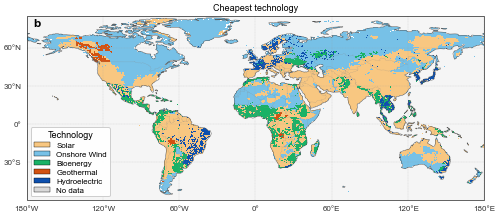

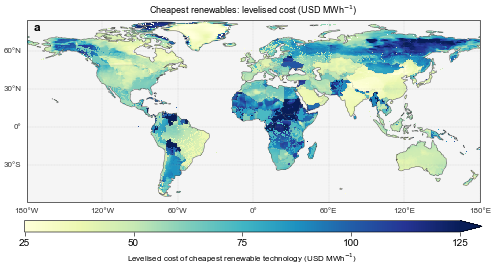

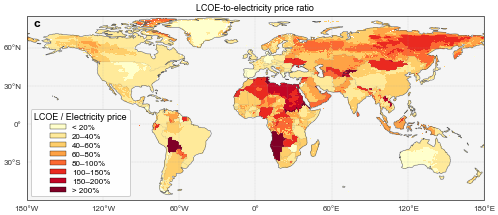

In [3]:
# ============================================
# Publication-quality global maps (Nature-style)
# Assumes existing: results (xarray Dataset), technology_palette (dict)
# ============================================
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import numpy as np
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --------------------------
# 1) Global style settings
# --------------------------
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "legend.fontsize": 8,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})

# --------------------------
# 2) Helper utilities
# --------------------------
def _get_lat_lon_names(da_or_ds):
    possible_lat = ["latitude", "lat", "Latitude", "y"]
    possible_lon = ["longitude", "lon", "Longitude", "x"]

    coords = list(da_or_ds.coords)
    lat_name = next((c for c in possible_lat if c in coords), None)
    lon_name = next((c for c in possible_lon if c in coords), None)

    if lat_name is None or lon_name is None:
        raise KeyError(f"Could not identify latitude/longitude coords from: {coords}")
    return lat_name, lon_name

def _setup_map_ax(ax, lon_vals, lat_vals, add_grid=True):
    ax.set_extent([float(np.nanmin(lon_vals)), float(np.nanmax(lon_vals)),
                   float(np.nanmin(lat_vals)), float(np.nanmax(lat_vals))], crs=ccrs.PlateCarree())

    # Map features
    ocean = cfeature.NaturalEarthFeature("physical", "ocean", "110m",
                                         edgecolor="none", facecolor="#f5f5f5")
    land = cfeature.NaturalEarthFeature("physical", "land", "110m",
                                        edgecolor="none", facecolor="#fcfcfc")
    borders = cfeature.NaturalEarthFeature("cultural", "admin_0_boundary_lines_land", "110m",
                                           edgecolor="#888888", facecolor="none")

    ax.add_feature(ocean, zorder=0)
    ax.add_feature(land, zorder=0)
    ax.add_feature(cfeature.COASTLINE.with_scale("110m"), linewidth=0.5, edgecolor="#555555", zorder=3)
    ax.add_feature(borders, linewidth=0.4, linestyle=":", zorder=3)

    if add_grid:
        gl = ax.gridlines(
            crs=ccrs.PlateCarree(),
            draw_labels=True,
            linewidth=0.3,
            color="#9e9e9e",
            alpha=0.6,
            linestyle="--",
            x_inline=False,
            y_inline=False
        )

        # Tick spacing requested: lon every 60°, lat every 30°
        gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
        gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))

        # Directional labels: E/W and N/S
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER

        # Label placement (journal-style: left + bottom only)
        gl.top_labels = False
        gl.right_labels = False
        gl.bottom_labels = True
        gl.left_labels = True

        # Label styling
        gl.xlabel_style = {"size": 8, "color": "#333333"}
        gl.ylabel_style = {"size": 8, "color": "#333333"}

def _panel_label(ax, label):
    ax.text(0.015, 0.985, label, transform=ax.transAxes, va="top", ha="left",
            fontsize=12, fontweight="bold")

# --------------------------
# 3) Plot 1: Cheapest technology (categorical)
# --------------------------
def plot_cheapest_technology_global_pub(
    ds,
    technology_palette,
    var_name="Cheapest_Technology",
    title="Cheapest technology",
    panel_label="a",
    filename=None
):
    if isinstance(ds, xr.Dataset):
        da = ds[var_name]
    else:
        da = ds

    lat_name, lon_name = _get_lat_lon_names(da)
    lats = da[lat_name].values
    lons = da[lon_name].values

    # Keep order from provided palette for consistent cross-figure mapping
    tech_order = list(technology_palette.keys())
    tech_to_code = {t: i for i, t in enumerate(tech_order)}

    code_da = xr.full_like(da, np.nan, dtype=float)
    for t, c in tech_to_code.items():
        code_da = xr.where(da == t, c, code_da)

    cmap = ListedColormap([technology_palette[t] for t in tech_order])
    norm = BoundaryNorm(np.arange(-0.5, len(tech_order) + 0.5, 1), cmap.N)

    fig = plt.figure(figsize=(8.2, 4.2), facecolor="white")
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
    _setup_map_ax(ax, lons, lats)

    mesh = ax.pcolormesh(
        lons, lats, code_da.values,
        transform=ccrs.PlateCarree(),
        cmap=cmap, norm=norm, shading="auto", rasterized=True
    )

    _panel_label(ax, panel_label)
    ax.set_title(title, pad=6)

    handles = [Patch(facecolor=technology_palette[t], edgecolor="black", linewidth=0.4, label=t) for t in tech_order]
    if np.isnan(code_da.values).any():
        handles.append(Patch(facecolor="#d9d9d9", edgecolor="black", linewidth=0.4, label="No data"))

    ax.legend(handles=handles, loc="lower left", frameon=True, framealpha=0.95,
              title="Technology", title_fontsize=9, borderpad=0.4, labelspacing=0.3)

    if filename:
        fig.savefig(f"{filename}.png")
        fig.savefig(f"{filename}.pdf")
    plt.show()

# --------------------------
# 4) Plot 2: Cheapest LCOE (continuous)
# --------------------------
def plot_lcoe_continuous_pub(
    ds,
    var_name="Calculated_LCOE",
    title="Cheapest renewables: LCOE (USD MWh$^{-1}$)",
    panel_label="b",
    vmin=0, vmax=100, ticks=(0, 25, 50, 75, 100),
    cmap="plasma_r",
    filename=None
):
    da = ds[var_name]
    lat_name, lon_name = _get_lat_lon_names(da)
    lats = da[lat_name].values
    lons = da[lon_name].values

    fig = plt.figure(figsize=(8.2, 4.2), facecolor="white")
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
    _setup_map_ax(ax, lons, lats)

    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    mesh = ax.pcolormesh(
        lons, lats, da.values,
        transform=ccrs.PlateCarree(),
        cmap=cmap, norm=norm, shading="auto", rasterized=True
    )

    _panel_label(ax, panel_label)
    ax.set_title(title, pad=6)

    cbar = fig.colorbar(mesh, ax=ax, orientation="horizontal", fraction=0.12, pad=0.08, extend="max", aspect=40)
    cbar.set_ticks(list(ticks))
    cbar.set_label("Levelised cost of cheapest renewable technology (USD MWh$^{-1}$)", labelpad=3)

    if filename:
        fig.savefig(f"{filename}.png")
        fig.savefig(f"{filename}.pdf")
    plt.show()

# --------------------------
# 5) Plot 3: LCOE / electricity price ratio (discrete)
# --------------------------
def plot_lcoe_price_ratio_discrete_pub(
    ds,
    lcoe_var="Calculated_LCOE",
    price_var="Benchmark_Price",
    # If Benchmark_Price is in USD/kWh and LCOE in USD/MWh, divide by 1000 to make ratio dimensionless:
    benchmark_is_usd_per_kwh=True,
    bins=(0.10, 0.20, 0.30, 0.40, 0.50),  # bin boundaries
    cmap="plasma_r",
    title="LCOE-to-electricity price ratio",
    panel_label="c",
    filename=None
):
    lcoe = ds[lcoe_var]
    price = ds[price_var]

    # Dimensionless ratio
    ratio = lcoe / (price * (1000 if benchmark_is_usd_per_kwh else 1.0))

    lat_name, lon_name = _get_lat_lon_names(ratio)
    lats = ratio[lat_name].values
    lons = ratio[lon_name].values

    bins = np.array(bins, dtype=float)
    if np.any(np.diff(bins) <= 0):
        raise ValueError("`bins` must be strictly increasing.")

    # Add under/over bounds for BoundaryNorm
    boundaries = np.concatenate(([-np.inf], bins, [np.inf]))
    base_cmap = plt.get_cmap(cmap, len(boundaries) - 1)
    norm = BoundaryNorm(boundaries, base_cmap.N)

    fig = plt.figure(figsize=(8.2, 4.2), facecolor="white")
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
    _setup_map_ax(ax, lons, lats)

    mesh = ax.pcolormesh(
        lons, lats, ratio.values,
        transform=ccrs.PlateCarree(),
        cmap=base_cmap, norm=norm, shading="auto", rasterized=True
    )

    _panel_label(ax, panel_label)
    ax.set_title(title, pad=6)

    # Discrete legend patches (cleaner than colorbar for categories)
    labels = [f"< {bins[0]*100:.0f}%"]
    labels += [f"{bins[i]*100:.0f}–{bins[i+1]*100:.0f}%" for i in range(len(bins)-1)]
    labels += [f"> {bins[-1]*100:.0f}%"]

    patches = [Patch(facecolor=base_cmap(i), edgecolor="black", linewidth=0.35, label=lab)
               for i, lab in enumerate(labels)]

    ax.legend(handles=patches, loc="lower left", frameon=True, framealpha=0.95,
              title="LCOE / Electricity price", title_fontsize=9, borderpad=0.4, labelspacing=0.3)

    if filename:
        fig.savefig(f"{filename}.png")
        fig.savefig(f"{filename}.pdf")
    plt.show()

# --------------------------
# 6) Example usage
# --------------------------
technology_palette = {
    "Solar":          "#F8C781",  # warm yellow-orange, hue ~35
    "Onshore Wind":   "#77C1E7",  # light sky blue
    "Bioenergy":      "#19B266",  # green
    "Geothermal":     "#D35211",  # deep orange / vermillion (heat)
    "Hydroelectric":  "#0E50AE",  # dark blue (water)
}

plot_cheapest_technology_global_pub(
    results,
    technology_palette=technology_palette,
    var_name="Cheapest_Technology",
    title="Cheapest technology",
    panel_label="b",
    filename="./OUTPUT_FOLDER_REAL_INPUT/CheapestTechnologyLocationCHECK"
)

plot_lcoe_continuous_pub(
    results,
    var_name="Calculated_LCOE",
    title="Cheapest renewables: levelised cost (USD MWh$^{-1}$)",
    panel_label="a",
    vmin=25, vmax=125, ticks=(25, 50, 75, 100, 125),
    cmap="YlGnBu",
    filename="./OUTPUT_FOLDER_REAL_INPUT/Cheapest_LCOECHECK"
)

plot_lcoe_price_ratio_discrete_pub(
    results,
    lcoe_var="Calculated_LCOE",
    price_var="Benchmark_Price",
    benchmark_is_usd_per_kwh=False,  # set False if already USD/MWh
    bins=(0.2, 0.4, 0.6, 0.8, 1, 1.5, 2),
    cmap="YlOrRd",
    title="LCOE-to-electricity price ratio",
    panel_label="c",
    filename="./OUTPUT_FOLDER_REAL_INPUT/Electricity_Price_LCOE_CheapestCHECK"
)



          region  n_paired    A_median  B_median  ratio_median_A_over_B  \
0         Africa        47  564.071983    478.26               1.219635   
1           Asia        44  468.881618    561.33               0.881033   
2         Europe        40  336.136963    233.92               1.404985   
3            LAC        29  391.164203    288.33               1.176083   
4  North America         5  352.484210    383.78               0.918454   
5        Oceania         8  639.571015    506.87               1.257582   

   ratio_median_B_over_A  
0               0.819917  
1               1.135042  
2               0.711788  
3               0.850280  
4               1.088786  
5               0.797066  


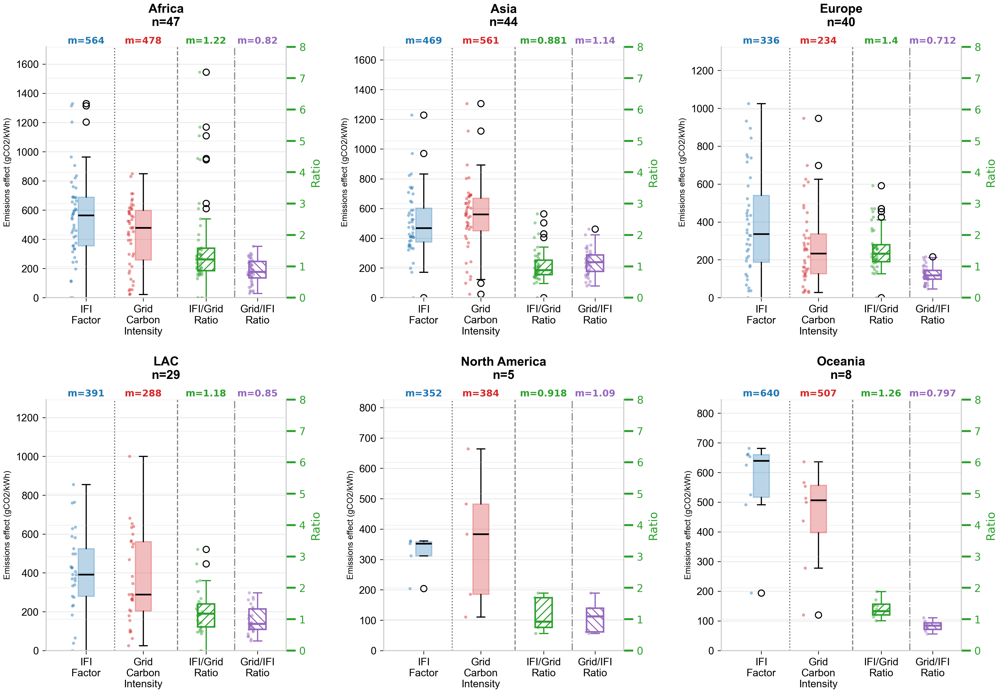

234


In [4]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns


import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns


def plot_regional_comparison(
    ds: xr.Dataset,
    var_a: str = "A",
    var_b: str = "B",
    region_var: str = "region",
    country_var: str = "country",
    ncols: int = 3,
    x_label_map: dict = None,
    ratio_label: str = "Emissions factor (gCO2/kWh)",
    figsize_per_panel=(4.6, 5.0),
    color_a="#1f77b4",
    color_b="#d62728",
    color_ratio="#2ca02c",
    point_alpha=0.45,
    point_size=3.0,
    jitter=0.05,
    point_left_offset=0.12,
    ratio_eps=1e-12,
    dpi=300,
    title="Regional comparison",
    return_stats=True,
):
    if var_a not in ds or var_b not in ds:
        raise KeyError(f"'{var_a}' and/or '{var_b}' not found in dataset variables.")
    if country_var not in ds:
        raise KeyError(f"'{country_var}' not found in dataset variables.")

    da_a = ds[var_a]
    da_b = ds[var_b]
    da_country = ds[country_var]

    if region_var in ds.coords:
        da_region = ds.coords[region_var]
    elif region_var in ds.data_vars:
        da_region = ds[region_var]
    else:
        raise KeyError(f"'{region_var}' not found as coordinate or data variable in dataset.")

    # Align all fields together
    da_a, da_b, da_country, da_region = xr.align(da_a, da_b, da_country, da_region, join="inner")

    # Country-level median for A and B, keep region mapping
    df = (
        pd.DataFrame({
            "A": da_a.values.ravel(),
            "B": da_b.values.ravel(),
            "country": da_country.values.ravel(),
            "region": da_region.values.ravel()
        })
        .groupby("country", as_index=False)
        .agg(
            A=("A", "median"),
            B=("B", "median"),
            region=("region", "first"),
        )
    )

    df["region"] = df["region"].astype(str)
    df_pair = df.dropna(subset=["A", "B"]).copy()
    df_pair = df_pair[np.abs(df_pair["B"]) > ratio_eps].copy()
    df_pair["ratio_A_over_B"] = df_pair["A"] / df_pair["B"]
    df_pair["ratio_B_over_A"] = df_pair["B"] / df_pair["A"].replace(0, np.nan)
    df_pair = df_pair.replace([np.inf, -np.inf], np.nan).dropna(subset=["ratio_A_over_B", "ratio_B_over_A"])

    regions = sorted(df_pair["region"].unique().tolist())
    n_regions = len(regions)
    if n_regions == 0:
        raise ValueError("No valid paired data found after filtering.")

    stats_df = (
        df_pair.groupby("region", as_index=False)
        .agg(
            n_paired=("ratio_A_over_B", "size"),
            A_median=("A", "median"),
            B_median=("B", "median"),
            ratio_median_A_over_B=("ratio_A_over_B", "median"),
            ratio_median_B_over_A=("ratio_B_over_A", "median"),
        )
    )

    nrows = int(np.ceil(n_regions / ncols))
    fig_w = figsize_per_panel[0] * ncols
    fig_h = figsize_per_panel[1] * nrows
    fig, axes = plt.subplots(nrows, ncols, figsize=(fig_w, fig_h), dpi=dpi, squeeze=False)

    sns.set_theme(style="whitegrid", context="talk")
    plt.rcParams.update({
        "font.family": "DejaVu Sans",
        "axes.linewidth": 1.0,
        "grid.linewidth": 0.6,
        "grid.alpha": 0.35,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
    })

    x_label_map = x_label_map or {}
    label_a = x_label_map.get(var_a, var_a)
    label_b = x_label_map.get(var_b, var_b)
    label_r = x_label_map.get("ratio", ratio_label)
    label_ir = x_label_map.get("inv_ratio", "Grid/IFI Ratio")

    # x positions
    x_a, x_b, x_r, x_ir = 0.0, 1.0, 2.1, 3.0
    x_sep1 = 0.5
    x_sep2 = 1.6
    x_sep3 = 2.6

    for i, reg in enumerate(regions):
        ax = axes[i // ncols, i % ncols]
        ax2 = ax.twinx()

        sub = df_pair[df_pair["region"] == reg]
        row = stats_df.loc[stats_df["region"] == reg].iloc[0]

        a_vals = sub["A"].values
        b_vals = sub["B"].values
        r_vals = sub["ratio_A_over_B"].values
        ir_vals = sub["ratio_B_over_A"].values

        # A and B on left y-axis
        bp = ax.boxplot(
            [a_vals, b_vals],
            positions=[x_a, x_b],
            widths=0.28,
            patch_artist=True,
            showfliers=True,
            medianprops=dict(color="black", linewidth=1.6),
            whiskerprops=dict(linewidth=1.1),
            capprops=dict(linewidth=1.1),
            boxprops=dict(linewidth=1.2),
        )
        bp["boxes"][0].set_facecolor(color_a)
        bp["boxes"][1].set_facecolor(color_b)
        bp["boxes"][0].set_edgecolor(color_a)
        bp["boxes"][1].set_edgecolor(color_b)
        bp["boxes"][0].set_alpha(0.30)
        bp["boxes"][1].set_alpha(0.30)

        # points for A/B (left-shifted)
        xa = (x_a - point_left_offset - 0.1) + np.random.uniform(-jitter, jitter, size=len(a_vals))
        xb = (x_b - point_left_offset - 0.1) + np.random.uniform(-jitter, jitter, size=len(b_vals))
        ax.scatter(xa, a_vals, s=point_size**2, alpha=point_alpha, color=color_a, linewidths=0, zorder=3)
        ax.scatter(xb, b_vals, s=point_size**2, alpha=point_alpha, color=color_b, linewidths=0, zorder=3)

        # Ratio boxplot on right y-axis (different style)
        bpr = ax2.boxplot(
            [r_vals],
            positions=[x_r],
            widths=0.30,
            patch_artist=True,
            showfliers=True,
            medianprops=dict(color=color_ratio, linewidth=2.0),
            whiskerprops=dict(linewidth=1.2, color=color_ratio),
            capprops=dict(linewidth=1.2, color=color_ratio),
            boxprops=dict(linewidth=1.5, color=color_ratio, linestyle="--"),
        )
        bpr["boxes"][0].set_facecolor("white")
        bpr["boxes"][0].set_edgecolor(color_ratio)
        bpr["boxes"][0].set_hatch("///")
        bpr["boxes"][0].set_alpha(1.0)
        
        bpri = ax2.boxplot(
            [ir_vals],
            positions=[x_ir],
            widths=0.30,
            patch_artist=True,
            showfliers=True,
            medianprops=dict(color="#9467bd", linewidth=2.0),
            whiskerprops=dict(linewidth=1.2, color="#9467bd"),
            capprops=dict(linewidth=1.2, color="#9467bd"),
            boxprops=dict(linewidth=1.5, color="#9467bd", linestyle="-."),
        )
        bpri["boxes"][0].set_facecolor("white")
        bpri["boxes"][0].set_edgecolor("#9467bd")
        bpri["boxes"][0].set_hatch("\\\\\\")

        xrj = (x_r - point_left_offset) + np.random.uniform(-jitter, jitter, size=len(r_vals))
        ax2.scatter(xrj, r_vals, s=point_size**2, alpha=point_alpha, color=color_ratio, linewidths=0, zorder=3)
        
        xirj = (x_ir - point_left_offset) + np.random.uniform(-jitter, jitter, size=len(ir_vals))
        ax2.scatter(xirj, ir_vals, s=point_size**2, alpha=point_alpha, color="#9467bd", linewidths=0, zorder=3)

        # separators
        ax.axvline(x=x_sep1, linestyle=":", color="0.4", linewidth=1.1)
        ax.axvline(x=x_sep2, linestyle="--", color="0.5", linewidth=1.1)
        ax.axvline(x=x_sep3, linestyle="-.", color="0.55", linewidth=1.1)
        
        # X ticks
        ax.set_xlim(-0.7, 3.5)
        ax.set_xticks([x_a, x_b, x_r, x_ir])
        ax.set_xticklabels([label_a, label_b, label_r, label_ir])


        ax.set_title(f"{reg}\nn={int(row['n_paired'])}", pad=20, weight="bold")
        ax.grid(axis="y", linestyle="-", alpha=0.28)
        ax.grid(axis="x", visible=False)

        # y labels
        ax.set_ylabel("Emissions effect (gCO2/kWh)")
        ax2.set_ylabel("Ratio", color=color_ratio)
        ax2.tick_params(axis="y", colors=color_ratio)

        # headroom for median text
        y_min, y_max = ax.get_ylim()
        ax.set_ylim(0, y_max + 0.22 * (y_max - y_min))
        r_min, r_max = ax2.get_ylim()
        ax2.set_ylim(0, 8)

        # median annotations
        ax.text(x_a, ax.get_ylim()[1] * 1.04, f"m={row['A_median']:.3g}",
                ha="center", va="top", fontsize=9, color=color_a, fontweight="semibold")
        ax.text(x_b, ax.get_ylim()[1] *  1.04, f"m={row['B_median']:.3g}",
                ha="center", va="top", fontsize=9, color=color_b, fontweight="semibold")
        ax2.text(x_r, ax2.get_ylim()[1] *  1.04, f"m={row['ratio_median_A_over_B']:.3g}",
                 ha="center", va="top", fontsize=9, color=color_ratio, fontweight="bold")
        ax2.text(x_ir, ax2.get_ylim()[1] *  1.04, f"m={row['ratio_median_B_over_A']:.3g}",
            ha="center", va="top", fontsize=9, color="#9467bd", fontweight="bold")


        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax2.spines["top"].set_visible(False)

    for j in range(n_regions, nrows * ncols):
        axes[j // ncols, j % ncols].axis("off")

    fig.tight_layout(rect=[0, 0, 1, 0.97])
    fig.savefig("./OUTPUT_FOLDER_REAL_INPUT/IFI_Ember_Country_ComparisonCHECK.png")

    if return_stats:
        return fig, stats_df
    return fig



# fig + summary table
fig, stats = plot_regional_comparison(
    results,
    var_a="IFI_Emissions_Factor",
    var_b="grid_intensity",
    region_var="region",
    country_var="country",
    ncols=3,
    ratio_label="IFI / Grid",
    x_label_map={
        "IFI_Emissions_Factor": "IFI\nFactor",
        "grid_intensity": "Grid\nCarbon\nIntensity",
        "ratio": "IFI/Grid\nRatio",
        "inv_ratio": "Grid/IFI\nRatio",
    },
    title="Regional comparison with ratio on secondary axis"
)

print(stats)
plt.show()
print(len(pd.unique(country_ds["country"].values.ravel())))

Globally: 58.4% of all locations have IRR > WACC; 67.6% of positive-IRR locations have IRR > WACC39.1% of all locations have IRR > WACC + 6%; 
Outside North America/Europe/Oceania: 46.4% of all locations have IRR > WACC; 58.4% of positive-IRR locations have IRR > WACC
Inside North America/Europe/Oceania: 69.0% of all locations have IRR > WACC; 74.7% of positive-IRR locations have IRR > WACC
(array(['Bioenergy', 'Geothermal', 'Hydroelectric', 'Onshore Wind',
       'Solar'], dtype='<U13'), array([ 4911,   662,  2236, 21602, 19826]))
Europe: 42.0% of all locations have IRR > WACC; 14.7% of all locations have IRR > WACC + 6%; 48.1% of positive-IRR locations have IRR > WACC
Asia: 64.5% of all locations have IRR > WACC; 46.9% of all locations have IRR > WACC + 6%; 70.4% of positive-IRR locations have IRR > WACC
Africa: 30.8% of all locations have IRR > WACC; 18.8% of all locations have IRR > WACC + 6%; 46.8% of positive-IRR locations have IRR > WACC
North America: 90.1% of all locations hav

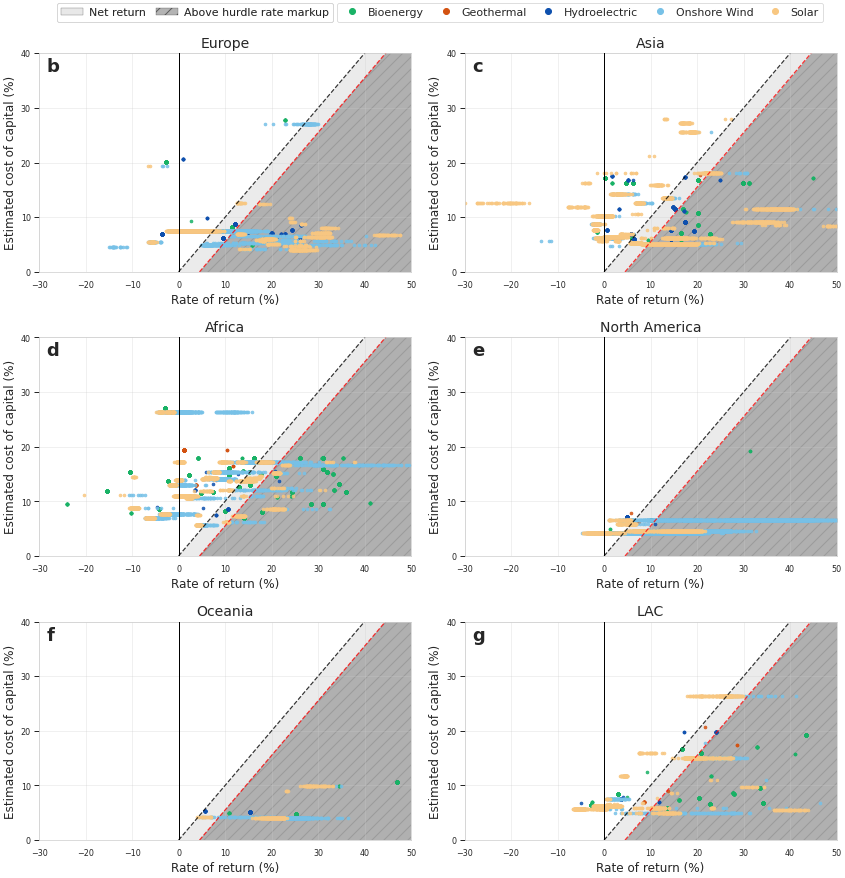

In [66]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from math import ceil
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon, Patch

def plot_coc_vs_ror_from_gridded_ds(
    ds,
    region_var="region",                  # 2D variable (lat, lon)
    tech_var="Cheapest_Technology",       # 2D variable (lat, lon)
    x_var="Estimated_WACC",               # x = rate of return proxy
    y_var="Calculated_LCOE",              # y = cost of capital proxy (set what you want)
    regions=None,                         # None => all unique non-null regions
    technologies=None,                    # None => all unique non-null technologies
    tech_colors=None,
    ncols=2,
    figsize_per_colrow=(6, 4),
    alpha=0.85,
    s=8,
    figure_title="Y vs X by Region (colored by technology)",  # kept arg, not used
    x_label="Rate of return (%)",
    y_label="Estimated cost of capital (%)",
    region_order=["Europe", "Asia", "Africa", "North America", "South America and the Caribbean", "Oceania"],
    sharex=True,
    sharey=True,
    grid=False,
):
    # Flatten arrays once
    r = ds[region_var].values.ravel()
    t = ds[tech_var].values.ravel()
    x = ds[x_var].values.ravel()
    y = ds[y_var].values.ravel()

    # Keep finite x/y
    base_mask = np.isfinite(x) & np.isfinite(y)

    # region/tech valid mask (not nan/None/"")
    r_valid = np.array([vv is not None and str(vv) != "nan" and str(vv).strip() != "" for vv in r])
    t_valid = np.array([vv is not None and str(vv) != "nan" and str(vv).strip() != "" for vv in t])

    mask = base_mask & r_valid & t_valid
    r, t, x, y = r[mask], t[mask], x[mask], y[mask]
    
    # ---------------------------------------------------------
    # Combined summary GLOBAL
    # ---------------------------------------------------------

    valid_out = np.isfinite(x) & np.isfinite(y)
    x_out = x[valid_out]
    y_out = y[valid_out]

    if x_out.size > 0:
        # Share of all outside locations where IRR > WACC
        share_all_out = np.mean(x_out > y_out) * 100.0
        share_hr = np.mean(x_out > y_out + 6) * 100.0

        # Share among positive-IRR outside locations where IRR > WACC
        pos_out = x_out > 0
        if pos_out.sum() > 0:
            share_pos_out = np.mean(x_out[pos_out] > y_out[pos_out]) * 100.0
        else:
            share_pos_out = np.nan

        print(
            "Globally: "
            f"{share_all_out:.1f}% of all locations have IRR > WACC; "
            f"{share_pos_out:.1f}% of positive-IRR locations have IRR > WACC"
            f"{share_hr:.1f}% of all locations have IRR > WACC + 6%; "
        )

    
    # ---------------------------------------------------------
    # Combined summary OUTSIDE North America, Europe, Oceania
    # ---------------------------------------------------------
    excluded_regions = {"North America", "Europe", "Oceania"}
    outside_mask = ~np.isin(r, list(excluded_regions))

    x_out = x[outside_mask]
    y_out = y[outside_mask]

    valid_out = np.isfinite(x_out) & np.isfinite(y_out)
    x_out = x_out[valid_out]
    y_out = y_out[valid_out]

    if x_out.size > 0:
        # Share of all outside locations where IRR > WACC
        share_all_out = np.mean(x_out > y_out) * 100.0

        # Share among positive-IRR outside locations where IRR > WACC
        pos_out = x_out > 0
        if pos_out.sum() > 0:
            share_pos_out = np.mean(x_out[pos_out] > y_out[pos_out]) * 100.0
        else:
            share_pos_out = np.nan

        print(
            "Outside North America/Europe/Oceania: "
            f"{share_all_out:.1f}% of all locations have IRR > WACC; "
            f"{share_pos_out:.1f}% of positive-IRR locations have IRR > WACC"
        )
    else:
        print("Outside North America/Europe/Oceania: no valid points")

    if regions is None:
        regions = np.unique(r).tolist()
        
    # ---------------------------------------------------------
    # Combined summary INSIDE North America, Europe, Oceania
    # ---------------------------------------------------------
    excluded_regions = {"North America", "Europe", "Oceania"}
    outside_mask = np.isin(r, list(excluded_regions))

    x_out = x[outside_mask]
    y_out = y[outside_mask]

    valid_out = np.isfinite(x_out) & np.isfinite(y_out)
    x_out = x_out[valid_out]
    y_out = y_out[valid_out]

    if x_out.size > 0:
        # Share of all outside locations where IRR > WACC
        share_all_out = np.mean(x_out > y_out) * 100.0

        # Share among positive-IRR outside locations where IRR > WACC
        pos_out = x_out > 0
        if pos_out.sum() > 0:
            share_pos_out = np.mean(x_out[pos_out] > y_out[pos_out]) * 100.0
        else:
            share_pos_out = np.nan

        print(
            "Inside North America/Europe/Oceania: "
            f"{share_all_out:.1f}% of all locations have IRR > WACC; "
            f"{share_pos_out:.1f}% of positive-IRR locations have IRR > WACC"
        )
    else:
        print("Inside North America/Europe/Oceania: no valid points")

    if regions is None:
        regions = np.unique(r).tolist()

    # Apply explicit ordering if provided
    if region_order is not None:
        # keep only regions that exist in data (and avoid duplicates)
        existing = set(regions)
        ordered = []
        for reg in region_order:
            if reg in existing and reg not in ordered:
                ordered.append(reg)

        # append any remaining regions not listed (optional behavior)
        remaining = [reg for reg in regions if reg not in ordered]
        regions = ordered + remaining
    if technologies is None:
        print(np.unique(t, return_counts=True))
        technologies = np.unique(t).tolist()

    if len(regions) == 0:
        raise ValueError("No valid regions found. Your 'region' variable appears empty/all-NaN.")

    if tech_colors is None:
        cmap = plt.get_cmap("tab10")
        tech_colors = {tech: cmap(i % 10) for i, tech in enumerate(technologies)}

    n_regions = len(regions)
    ncols = min(ncols, n_regions)
    nrows = ceil(n_regions / ncols)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_colrow[0]*ncols, figsize_per_colrow[1]*nrows),
        sharex=sharex, sharey=sharey
    )
    axes = np.atleast_1d(axes).ravel()
    panel_labels = list("bcdefg")

    for i, region in enumerate(regions):
        ax = axes[i]
        reg_mask = (r == region)
        
        # --- Share where Benchmark_IRR > Estimated_WACC (i.e., x > y) ---
        xr_reg = x[reg_mask]
        yr_reg = y[reg_mask]

        valid_reg = np.isfinite(xr_reg) & np.isfinite(yr_reg)
        xr_reg = xr_reg[valid_reg]
        yr_reg = yr_reg[valid_reg]

        if xr_reg.size > 0:
            # 1) Share of all valid points where IRR > WACC
            share_all = np.mean(xr_reg > yr_reg) * 100.0
            share_hr = np.mean(xr_reg > yr_reg + 6) * 100.0

            # 2) Among positive-return points (IRR > 0), share where IRR > WACC
            pos_mask = xr_reg > 0
            if pos_mask.sum() > 0:
                share_pos = np.mean(xr_reg[pos_mask] > yr_reg[pos_mask]) * 100.0
            else:
                share_pos = np.nan

            print(
                f"{region}: "
                f"{share_all:.1f}% of all locations have IRR > WACC; "
                f"{share_hr:.1f}% of all locations have IRR > WACC + 6%; "
                f"{share_pos:.1f}% of positive-IRR locations have IRR > WACC"
            )
        else:
            print(f"{region}: no valid points")

        for tech in technologies:
            m = reg_mask & (t == tech)
            if np.any(m):
                ax.scatter(x[m], y[m], s=s, alpha=alpha, color=tech_colors.get(tech, "gray"))

        # Keep region labels (not removed by your request)
        ax.set_title(str(region), fontsize=14)

        # Show labels on EVERY subplot
        ax.set_xlabel(x_label, fontsize=12)
        ax.set_ylabel(y_label, fontsize=12)

        if grid:
            ax.grid(True, alpha=0.25)
            
        if i < len(panel_labels):
            ax.text(
                0.02, 0.98, panel_labels[i],
                transform=ax.transAxes,   # axes-relative coordinates
                ha="left", va="top",
                fontsize=18, fontweight="bold"
            )

    for j in range(n_regions, len(axes)):
        axes[j].set_visible(False)

    yticks = np.arange(0, 55, 10)
    xticks = np.arange(-50, 55, 10)

    for ax in axes[:n_regions]:
        ax.set_xticks(xticks)
        ax.set_yticks(yticks)

        # force tick labels visible on all shared axes
        ax.tick_params(axis="x", which="both", labelbottom=True)
        ax.tick_params(axis="y", which="both", labelleft=True)

        # x-limits and y limits
        ax.set_xlim([-30, 50])
        ymin, ymax = ax.get_ylim()
        ax.set_ylim([0, 40])
        xmin, xmax = ax.get_xlim()
        
        # Remove internal padding so data/patch reaches axes bounds
        #ax.margins(x=0, y=0)

        # triangle
        tri = Polygon(
            [(0, 0), (xmax, 0), (xmax, ymax)],
            closed=True,
            facecolor="lightgrey",
            edgecolor="none",
            alpha=0.45,
            zorder=0
        )
        ax.add_patch(tri)
        

        # diagonals
        hurdle_rate = 4.5
        ax.plot([0, xmax], [0, ymax], "--", color="black", lw=1.2, alpha=0.8)
        ax.plot([hurdle_rate, xmax], [0, ymax - hurdle_rate], "--", color="red", lw=1.2, alpha=0.8)
        
        tri = Polygon(
            [(hurdle_rate, 0), (xmax, 0), (xmax, ymax-hurdle_rate)],
            closed=True,
            facecolor="dimgrey",
            edgecolor="grey",
            hatch="//",
            alpha=0.45,
            zorder=0
        )
        ax.add_patch(tri)

        # --- Move y-axis to center (x=0) but keep full box ---
        ax.spines["left"].set_position(("data", -30))#entered y-axis
        ax.yaxis.set_ticks_position("left")
        ax.yaxis.set_label_position("left")

        # keep rectangular box visible
        for side in ["top", "right", "bottom"]:
            ax.spines[side].set_visible(True)

        # draw left border too (since left spine moved to x=0)
        ax.plot([0, 0], [ymin, ymax], color="black", lw=1.0, zorder=3)
        
        

    
    # ---------- Two legends on the top line (single row each) ----------
    point_handles = [
        Line2D([0], [0], marker='o', linestyle='', color=tech_colors[k], label=str(k), markersize=6)
        for k in technologies
    ]

    shading_mapping = {
        "Net return": "lightgrey",
        "Above hurdle rate markup": "dimgrey"
    }
    shading_handles = [
        Patch(
            facecolor=shading_mapping[label],
            edgecolor="black",
            linewidth=0.4,
            alpha=0.45,
            hatch="//" if "hurdle" in label.lower() else None,
            label=label
        )
        for label in shading_mapping
    ]

    # Left legend: shading meaning
    leg1 = fig.legend(
        handles=shading_handles,
        loc="upper left",
        bbox_to_anchor=(0.07, 1.03),
        ncol=len(shading_handles),   # one row
        frameon=True,
        fontsize=11,
        columnspacing=1.0,
        handletextpad=0.5,
        borderpad=0.4
    )

    # Right legend: technology colors
    leg2 = fig.legend(
        handles=point_handles,
        loc="upper right",
        bbox_to_anchor=(0.97, 1.03),
        ncol=len(point_handles),     # one row
        frameon=True,
        fontsize=11,
        columnspacing=1.0,
        handletextpad=0.4
    )

    fig.add_artist(leg1)
    
    plt.tight_layout(rect=[0, 0, 1, 0.90])  # reserve top 10% for legends
    fig.subplots_adjust(hspace=0.1, top=0.9)

    plt.rcParams["axes.xmargin"] = 0
    plt.rcParams["axes.ymargin"] = 0
    plt.tight_layout()
    fig.subplots_adjust(hspace=0.3)
    return fig, axes

# Example: custom colors and subset selection
tech_palette = {
    "Solar":          "#F8C781",  # warm yellow-orange, hue ~35
    "Onshore Wind":   "#77C1E7",  # light sky blue
    "Bioenergy":      "#19B266",  # green
    "Geothermal":     "#D35211",  # deep orange / vermillion (heat)
    "Hydroelectric":  "#0E50AE",  # dark blue (water)
}

fig, axes = plot_coc_vs_ror_from_gridded_ds(
    ds=results,
    region_var="region",
    tech_var="Cheapest_Technology",
    x_var="Benchmark_IRR",
    y_var="Estimated_WACC",   # or whichever y you intend
    regions=None,              # all unique regions
    technologies=None,
    tech_colors=tech_palette
)

plt.savefig("./OUTPUT_FOLDER_REAL_INPUT/CoC-Return_CheapestCHECK.png")
plt.show()

# print(results.variables)

192.31834372682533
-100.0


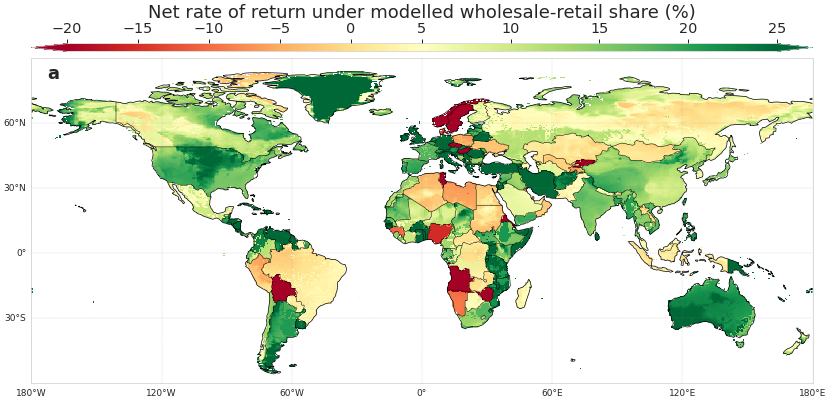

64.88173827141402
-100.0


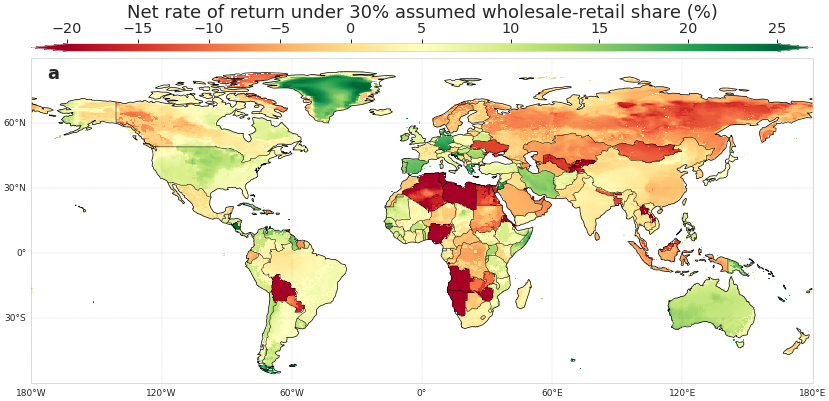

87.27926222174003
-100.0


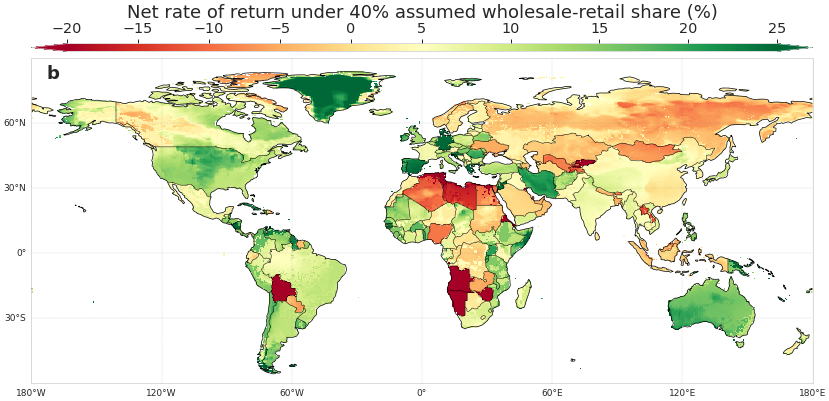

109.6744228351186
-100.0


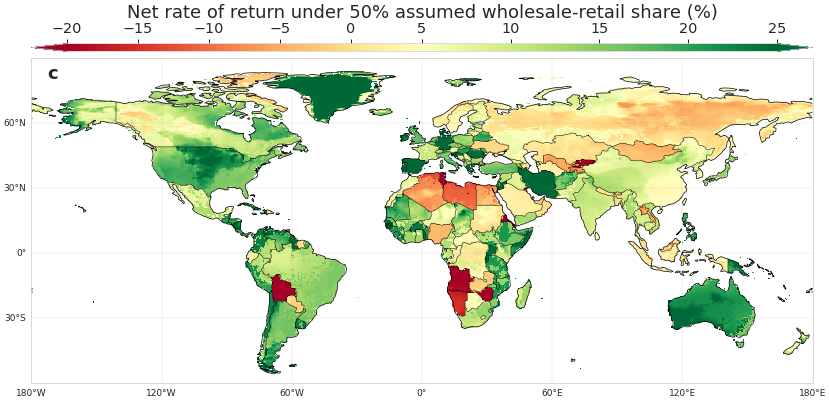

132.06935476452176
-100.0


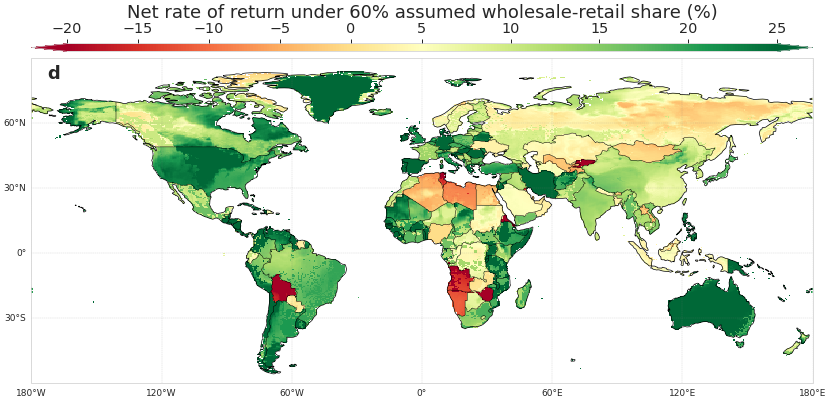

154.46424520462384
-100.0


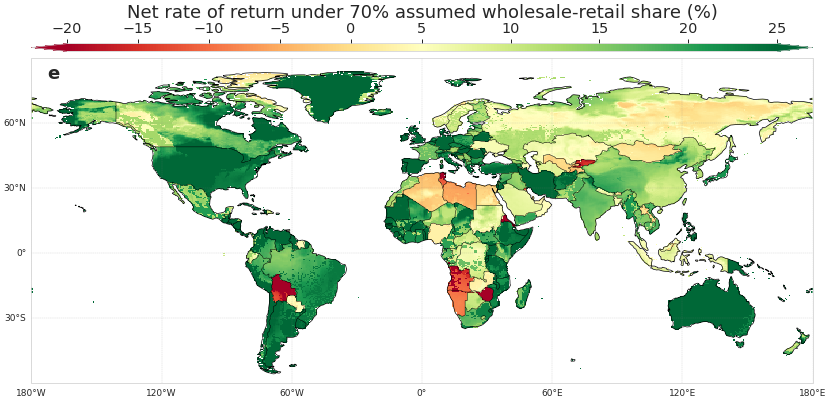

In [69]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.colors as colors

for i, benchmark in enumerate(["", "30", "40", "50", "60", "70"]):
    alphabet = ["a", "b", "c", "d", "e"]
    if benchmark == "":
        graphmarking = "a"
        number = "modelled wholesale-retail share"
    else:
        graphmarking = alphabet[i-1]
        number = benchmark +"% assumed wholesale-retail share"
    results["IRR_net_"+str(benchmark)] = results["Benchmark_IRR"+str(benchmark)] - results["Estimated_WACC"]
    #da = results["IRR_net_"+str(benchmark)]
    da = results["Benchmark_IRR"+str(benchmark)]
    print(np.nanmax(da))
    print(np.nanmin(da))

    fig = plt.figure(figsize=(14, 6))
    ax = plt.axes(projection=ccrs.PlateCarree())

    # Plot raster
    mesh = ax.pcolormesh(
        da["longitude"],
        da["latitude"],
        da.values,
        transform=ccrs.PlateCarree(),
        cmap="RdYlGn",
        norm=colors.TwoSlopeNorm(vmin=-20, vcenter=5, vmax=25),
        shading="auto"
    )

    # Coastlines + borders
    ax.coastlines(linewidth=0.7)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.text(0.02, 0.98, graphmarking,
            transform=ax.transAxes,   # axes-relative coordinates
            ha="left", va="top",
            fontsize=18, fontweight="bold"
        )

    # Limit to latitudes above -65
    ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())

    # Longitude/latitude ticks + labels
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=0.4,
        color="gray",
        alpha=0.4,
        linestyle="--"
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.FixedLocator([-180, -120, -60, 0, 60, 120, 180])
    gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {"size": 9}
    gl.ylabel_style = {"size": 9}

    # Colorbar above, thin, map-width
    pos = ax.get_position()
    cax = fig.add_axes([pos.x0, pos.y1 + 0.015, pos.width, 0.018])
    cbar = fig.colorbar(mesh, cax=cax, orientation="horizontal", extend="both")
    cbar.set_label("Net rate of return under " + number + " (%)", fontsize=18)
    cbar.ax.xaxis.set_ticks_position("top")
    cbar.ax.xaxis.set_label_position("top")
    cbar.ax.tick_params(labelsize='large')
    plt.savefig("./OUTPUT_FOLDER_REAL_INPUT/IRR_Net_Global_"+ str(benchmark) + "CHECK.png")
    plt.show()

/Users/lukehatton/opt/anaconda3/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: The following kwargs were not used by contour: 'edgecolor'
  result = super().contourf(*args, **kwargs)


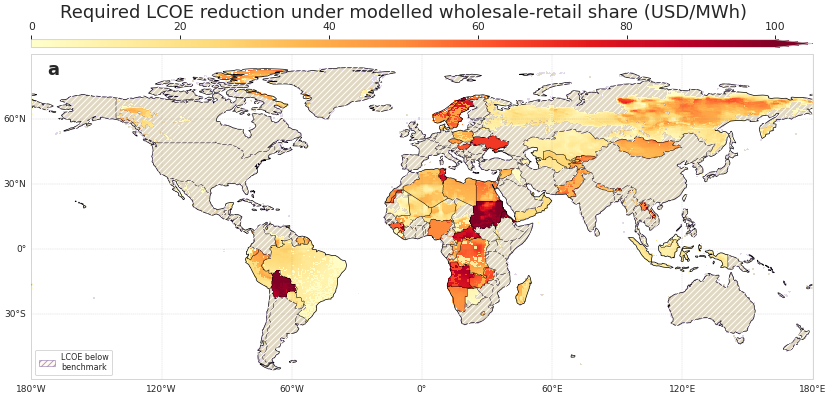

/Users/lukehatton/opt/anaconda3/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: The following kwargs were not used by contour: 'edgecolor'
  result = super().contourf(*args, **kwargs)


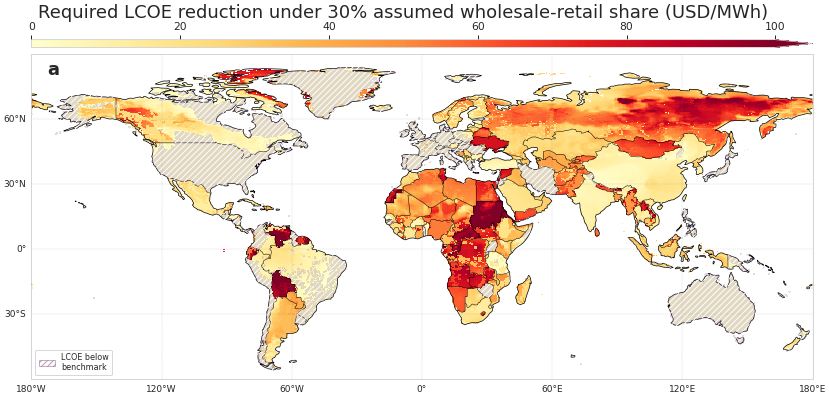

/Users/lukehatton/opt/anaconda3/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: The following kwargs were not used by contour: 'edgecolor'
  result = super().contourf(*args, **kwargs)


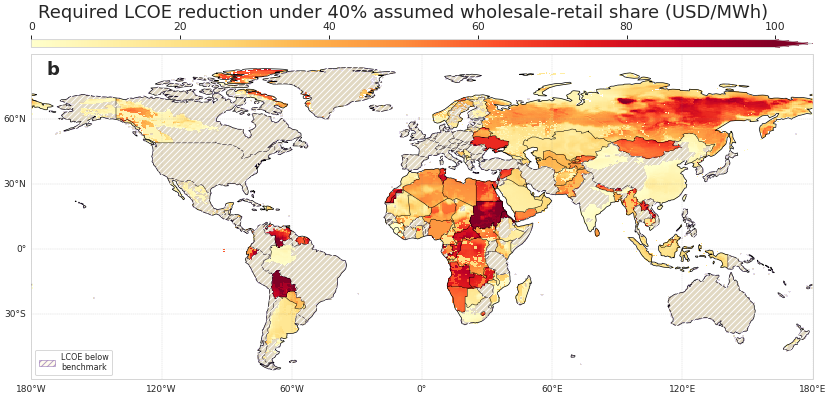

/Users/lukehatton/opt/anaconda3/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: The following kwargs were not used by contour: 'edgecolor'
  result = super().contourf(*args, **kwargs)


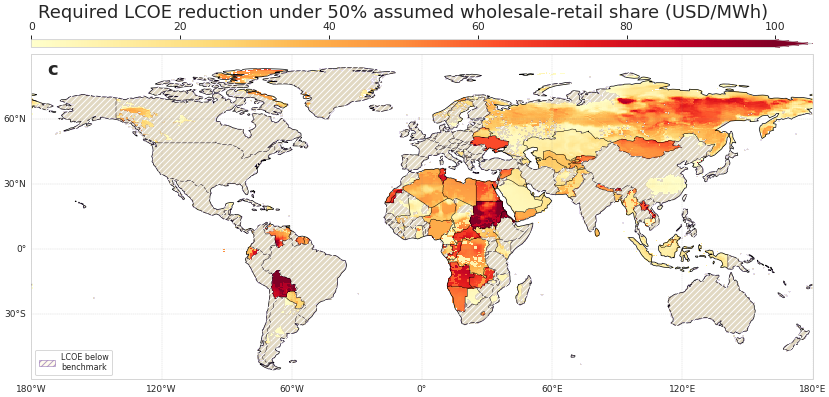

/Users/lukehatton/opt/anaconda3/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: The following kwargs were not used by contour: 'edgecolor'
  result = super().contourf(*args, **kwargs)


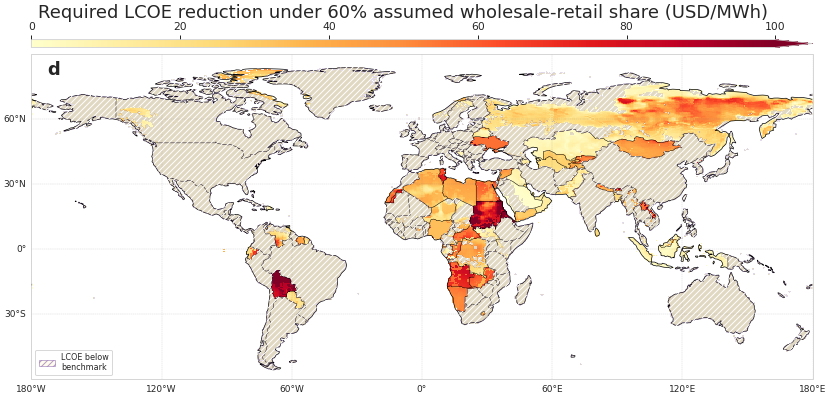

/Users/lukehatton/opt/anaconda3/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: The following kwargs were not used by contour: 'edgecolor'
  result = super().contourf(*args, **kwargs)


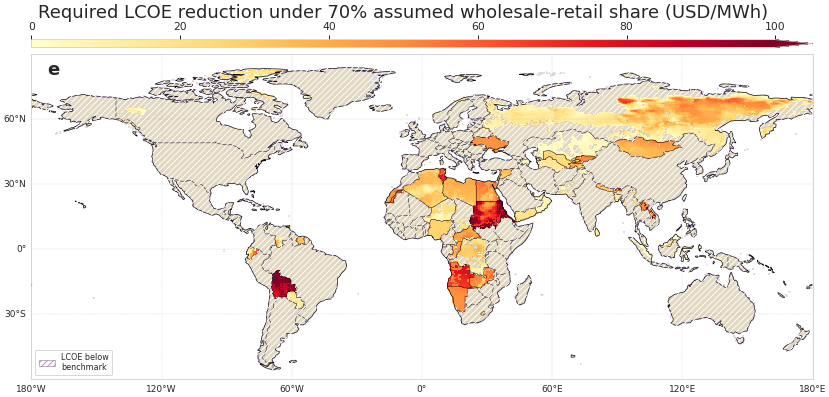

In [41]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.colors as colors

for i, benchmark in enumerate(["", "30", "40", "50", "60", "70"]):
    alphabet = ["a", "b", "c", "d", "e"]
    if benchmark == "":
        graphmarking = "a"
        number = "modelled wholesale-retail share"
    else:
        graphmarking = alphabet[i-1]
        number = benchmark +"% assumed wholesale-retail share"
    results["Financing_Gap"+str(benchmark)] = results["Calculated_LCOE"] -results["Benchmark_LCOE"+str(benchmark)]*1000
    #da = results["IRR_net_"+str(benchmark)]
    da = results["Financing_Gap"+str(benchmark)]
    shade_mask = (results["Calculated_LCOE"] < results["Benchmark_LCOE"+str(benchmark)]*1000).values.astype(float)


    fig = plt.figure(figsize=(14, 6))
    ax = plt.axes(projection=ccrs.PlateCarree())

    # Plot raster
    mesh = ax.pcolormesh(
        da["longitude"],
        da["latitude"],
        da.values,
        transform=ccrs.PlateCarree(),
        cmap="YlOrRd",
        norm=colors.TwoSlopeNorm(vmin=0, vcenter=50, vmax=100),
        shading="auto"
    )

    # Coastlines + borders
    ax.coastlines(linewidth=0.7)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.text(0.02, 0.98, graphmarking,
            transform=ax.transAxes,   # axes-relative coordinates
            ha="left", va="top",
            fontsize=18, fontweight="bold"
        )

    # Limit to latitudes above -65
    ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())


    # Hatched + translucent shading where Calculated_LCOE < Benchmark
    ax.contourf(da["longitude"],da["latitude"], shade_mask,
        levels=[0.5, 1.5],
        hatches=["////"],
        colors="none",              # hatch-only layer (no fill)
        edgecolor="#3b1f5e",        # hatch line color
        transform=ccrs.PlateCarree(),
        zorder=3
    )

    # Translucent fill layer underneath
    ax.contourf(da["longitude"],da["latitude"], shade_mask,
        levels=[0.5, 1.5],
        colors=["#6a3d9a"],
        alpha=0.2,
        transform=ccrs.PlateCarree(),
        zorder=2.8
    )

    # Legend for hatched shading
    shaded_patch = mpatches.Patch(
        facecolor="cornsilk",
        edgecolor="#6a3d9a",
        hatch="////",
        alpha=0.5,
        label="LCOE below\nbenchmark"
    )
    ax.legend(
        handles=[shaded_patch],
        loc="lower left",
        frameon=True,
        framealpha=0.95,
        title_fontsize=8,
        fontsize=8
    )

    # Longitude/latitude ticks + labels
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=0.4,
        color="gray",
        alpha=0.4,
        linestyle="--"
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.FixedLocator([-180, -120, -60, 0, 60, 120, 180])
    gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {"size": 9}
    gl.ylabel_style = {"size": 9}

    # Colorbar above, thin, map-width
    pos = ax.get_position()
    cax = fig.add_axes([pos.x0, pos.y1 + 0.015, pos.width, 0.018])
    cbar = fig.colorbar(mesh, cax=cax, orientation="horizontal", extend="max")
    cbar.set_label("Required LCOE reduction under " + number + " (USD/MWh)", fontsize=18)
    cbar.ax.xaxis.set_ticks_position("top")
    cbar.ax.xaxis.set_label_position("top")
    cbar.ax.tick_params(labelsize='large')
    plt.savefig("./OUTPUT_FOLDER_REAL_INPUT/Financing_Gap_Global_"+ str(benchmark) + "CHECK.png")
    plt.show()

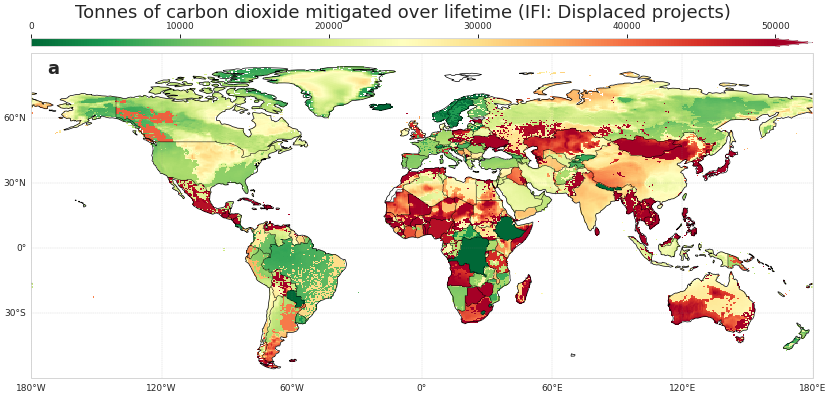

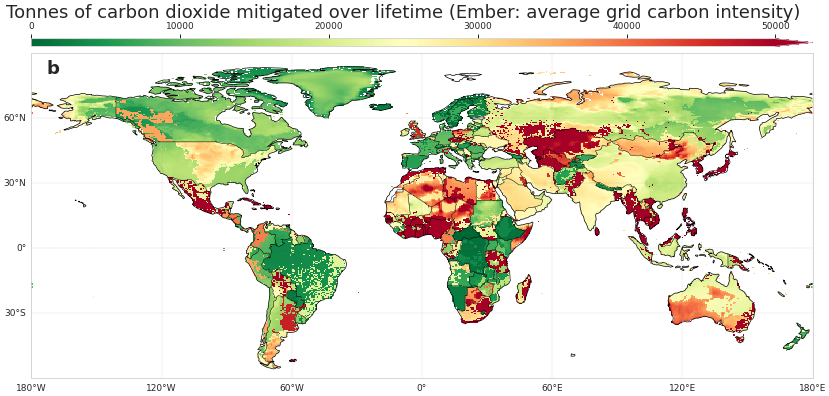

In [32]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER


for i, x in enumerate(["abatement_MW", "abatement_CI"]):
    da = results[x]
    source_mapping = {"abatement_MW":"IFI: Displaced projects", "abatement_CI":"Ember: average grid carbon intensity"}
    label = ["a", "b"]
    source = source_mapping.get(x)
    fig = plt.figure(figsize=(14, 6))
    ax = plt.axes(projection=ccrs.PlateCarree())

    # Plot raster
    mesh = ax.pcolormesh(
        da["longitude"],
        da["latitude"],
        da.values,
        transform=ccrs.PlateCarree(),
        cmap="RdYlGn_r",
        vmin=0, vmax=50000,
        shading="auto"
    )

    # Coastlines + borders
    ax.coastlines(linewidth=0.7)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.text(0.02, 0.98,label[i],
            transform=ax.transAxes,   # axes-relative coordinates
            ha="left", va="top",
            fontsize=18, fontweight="bold"
        )

    # Limit to latitudes above -65
    ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())

    # Longitude/latitude ticks + labels
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=0.4,
        color="gray",
        alpha=0.4,
        linestyle="--"
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.FixedLocator([-180, -120, -60, 0, 60, 120, 180])
    gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {"size": 9}
    gl.ylabel_style = {"size": 9}

    # Colorbar above, thin, map-width
    pos = ax.get_position()
    cax = fig.add_axes([pos.x0, pos.y1 + 0.015, pos.width, 0.018])
    cbar = fig.colorbar(mesh, cax=cax, orientation="horizontal", extend="max")
    cbar.set_label(f"Tonnes of carbon dioxide mitigated over lifetime ({source})", fontsize=18)
    cbar.ax.xaxis.set_ticks_position("top")
    cbar.ax.xaxis.set_label_position("top")
    cbar.ax.tick_params(labelsize='medium')
    plt.savefig(f"./OUTPUT_FOLDER_REAL_INPUT/Global_Abatement_{x}CHECK.png")
    plt.show()

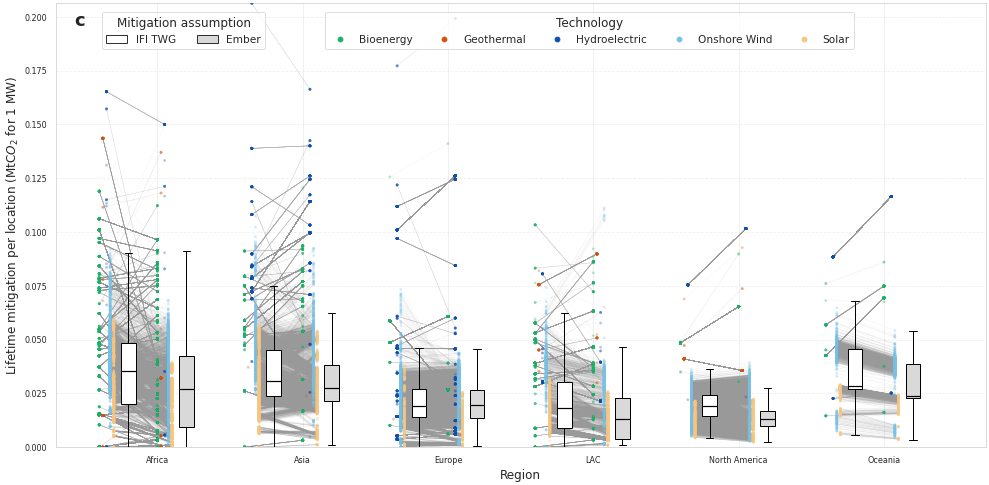

In [78]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def ds_to_mitigation_df(
    ds,
    region_var="region",
    tech_var="Cheapest_Technology",
    mit1_var="Mitigation_est1",
    mit2_var="Mitigation_est2",
    dropna=True
):
    """
    Convert a gridded xarray.Dataset to a long DataFrame with:
      - location_id (for one-to-one pairing across assumptions)
      - region
      - technology
      - mitigation
      - assumption (label for the mitigation assumption)
    """
    region = ds[region_var]
    tech = ds[tech_var]
    mit1 = ds[mit1_var]
    mit2 = ds[mit2_var]

    # Broadcast region/tech to mitigation dims if needed
    region = region.broadcast_like(mit1)
    tech = tech.broadcast_like(mit1)

    # Stable location id from flattened grid index
    n = region.values.size
    loc_id = np.arange(n)

    # DataFrame for assumption 1
    df1 = pd.DataFrame({
        "location_id": loc_id,
        "region": region.values.ravel(),
        "technology": tech.values.ravel(),
        "mitigation": mit1.values.ravel(),
        "assumption": mit1_var,
    })

    # DataFrame for assumption 2
    df2 = pd.DataFrame({
        "location_id": loc_id,
        "region": region.values.ravel(),
        "technology": tech.values.ravel(),
        "mitigation": mit2.values.ravel(),
        "assumption": mit2_var,
    })

    df = pd.concat([df1, df2], ignore_index=True)

    if dropna:
        df = df.replace([np.inf, -np.inf], np.nan)
        df = df.dropna(subset=["location_id", "region", "technology", "mitigation", "assumption"])

    # convert to MtCO2/year (or desired unit)
    df["mitigation"] = df["mitigation"] / 1e6

    return df


def plot_mitigation_distributions_by_region_with_left_jitter(
    df,
    region_order=None,
    assumption_order=None,
    figsize=(12, 6),
    y_label="Annual mitigation per location (tCO₂/year)",
    tech_palette=None,
    jitter_alpha=0.4,
    jitter_size=10,
    x_offset=0.18,            # separation between assumptions within a region
    jitter_base_offset=0.15,  # how far left of each box the jitter cloud is centered
    output_path=None,
    connect_pairs=True,       # NEW: draw one-to-one lines between assumptions
    pair_line_alpha=0.12,
    pair_line_width=0.4,
    pair_line_color="0.6",
    pair_sample_frac=1.0,     # NEW: subsample paired lines for performance/readability
    random_seed=42
):
    """
    Plot mitigation distributions per region for two assumptions using
    two offset boxplots per region, technology-colored jitter points left of each box,
    and optional one-to-one paired lines per location behind the boxplots.

    Required for paired lines: df must contain 'location_id'.
    """

    df = df.copy()
    df = df.dropna(subset=["region", "technology", "mitigation", "assumption"])

    # Infer order if needed
    if region_order is None:
        region_order = sorted(df["region"].unique().tolist())
    if assumption_order is None:
        assumption_order = list(df["assumption"].unique())

    if len(assumption_order) != 2:
        raise ValueError("This function currently assumes exactly 2 mitigation assumptions.")

    # Categorical consistency
    df["region"] = pd.Categorical(df["region"], categories=region_order, ordered=True)
    df["assumption"] = pd.Categorical(df["assumption"], categories=assumption_order, ordered=True)

    # Technology palette
    techs = df["technology"].dropna().unique().tolist()
    if tech_palette is None:
        cmap = plt.get_cmap("tab10")
        tech_palette = {tech: cmap(i % 10) for i, tech in enumerate(techs)}

    tech_to_idx = {tech: i for i, tech in enumerate(sorted(techs))}
    n_tech = len(techs)
    tech_center = (n_tech - 1) / 1.0 if n_tech > 0 else 0.0

    fig, ax = plt.subplots(figsize=figsize)

    # x positions by region
    base_x_positions = np.arange(len(region_order))
    region_to_base_x = {reg: base_x_positions[i] for i, reg in enumerate(region_order)}

    # left/right assumption mapping
    ass_to_sign = {
        assumption_order[0]: -1.0,  # left
        assumption_order[1]: +1.0,  # right
    }

    # -------------------------
    # Build boxplot data
    # -------------------------
    box_positions = []
    box_data = []
    box_assumptions = []
    ra_to_xpos = {}

    for i, region in enumerate(region_order):
        for assumption in assumption_order:
            df_ra = df[(df["region"] == region) & (df["assumption"] == assumption)]
            if df_ra.empty:
                continue

            x_pos = base_x_positions[i] + ass_to_sign[assumption] * x_offset
            vals = df_ra["mitigation"].values

            box_positions.append(x_pos)
            box_data.append(vals)
            box_assumptions.append(assumption)
            ra_to_xpos[(region, assumption)] = x_pos

    if len(box_data) == 0:
        raise ValueError(
            "No data for any (region, assumption) combination.\n"
            f"Regions in data: {df['region'].unique()}\n"
            f"Assumptions in data: {df['assumption'].unique()}"
        )

    bp = ax.boxplot(
        box_data,
        positions=box_positions,
        widths=0.10,
        patch_artist=True,
        showfliers=False,
        zorder=2
    )

    # Style boxes
    assumption_facecolors = {
        assumption_order[0]: "white",
        assumption_order[1]: "#d9d9d9",
    }
    assumption_edgecolor = "black"

    for patch, assumption in zip(bp["boxes"], box_assumptions):
        patch.set_facecolor(assumption_facecolors.get(assumption, "white"))
        patch.set_edgecolor(assumption_edgecolor)
        patch.set_linewidth(1.0)

    for median in bp["medians"]:
        median.set_color("black")
        median.set_linewidth(1.2)

    # -------------------------
    # Optional paired lines (behind boxplots and jitter)
    # -------------------------
    if connect_pairs:
        if "location_id" not in df.columns:
            raise ValueError(
                "connect_pairs=True requires a 'location_id' column. "
                "Use the updated ds_to_mitigation_df() that adds location_id."
            )

        pair_df = (
            df.pivot_table(
                index=["location_id", "region", "technology"],
                columns="assumption",
                values="mitigation",
                aggfunc="first"
            )
            .reset_index()
        )

        # keep only complete pairs
        pair_df = pair_df.dropna(subset=[assumption_order[0], assumption_order[1], "region"])

        # optional subsample
        if pair_sample_frac < 1.0:
            pair_sample_frac = max(0.0, min(1.0, pair_sample_frac))
            pair_df = pair_df.sample(frac=pair_sample_frac, random_state=random_seed)

        # build line segments efficiently
        x1, x2, y1, y2 = [], [], [], []
        for _, row in pair_df.iterrows():
            reg = row["region"]
            tech = row["technology"]

            if reg not in region_to_base_x:
                continue

            base = region_to_base_x[reg]

            # --- same tech offset logic as jitter ---
            tech_idx = tech_to_idx.get(tech, 0)
            if n_tech > 1:
                tech_off = (tech_idx - tech_center) * (jitter_base_offset / tech_center)
            else:
                tech_off = 0.0

            # line endpoints aligned with jitter "bands"
            xa = base + ass_to_sign[assumption_order[0]] * x_offset - jitter_base_offset + tech_off
            xb = base + ass_to_sign[assumption_order[1]] * x_offset - jitter_base_offset + tech_off

            x1.append(xa)
            x2.append(xb)
            y1.append(row[assumption_order[0]])
            y2.append(row[assumption_order[1]])

        for xa, xb, ya, yb in zip(x1, x2, y1, y2):
            ax.plot(
                [xa, xb], [ya, yb],
                color=pair_line_color,
                alpha=pair_line_alpha,
                linewidth=pair_line_width,
                zorder=1
            )

    # -------------------------
    # Jitter points (left of each box)
    # -------------------------
    x_jitter = []
    y_vals = []
    colors = []

    rng = np.random.default_rng(random_seed)

    for _, row in df.iterrows():
        reg = row["region"]
        ass = row["assumption"]
        tech = row["technology"]
        mit = row["mitigation"]

        key = (reg, ass)
        if key not in ra_to_xpos:
            continue

        x_base = ra_to_xpos[key]

        tech_idx = tech_to_idx.get(tech, 0)
        if n_tech > 1:
            tech_off = (tech_idx - tech_center) * (jitter_base_offset / tech_center)
        else:
            tech_off = 0.0

        x_val = x_base - jitter_base_offset + tech_off #+ rng.uniform(-0.01, 0.01)

        x_jitter.append(x_val)
        y_vals.append(mit)
        colors.append(tech_palette.get(tech, "gray"))

    if x_jitter:
        ax.scatter(
            x_jitter, y_vals,
            s=jitter_size,
            alpha=jitter_alpha,
            c=colors,
            edgecolors="none",
            zorder=3
        )

    # -------------------------
    # Aesthetics
    # -------------------------
    ax.set_xticks(base_x_positions)
    ax.set_xticklabels(region_order)
    ax.set_ylabel(y_label, fontsize=12)
    ax.set_xlabel("Region", fontsize=12)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    # adjust as needed:
    # ax.set_ylim([-0.01, 0.2])

    # -------------------------
    # Legends
    # -------------------------
    assumption_mapping = {"abatement_MW": "IFI TWG", "abatement_CI": "Ember"}
    assumption_patches = [
        Patch(
            facecolor=assumption_facecolors[a],
            edgecolor=assumption_edgecolor,
            label=assumption_mapping.get(a, a)
        )
        for a in assumption_order
    ]

    tech_handles = [
        Line2D([0], [0], marker="o", linestyle="", color=tech_palette[t], label=t)
        for t in sorted(techs)
    ]

    leg1 = ax.legend(
        handles=assumption_patches,
        title="Mitigation assumption",
        loc="upper left",
        bbox_to_anchor=(0.05, 0.98),
        ncol=2,
        borderaxespad=0.0,
        fontsize=10.5,
        title_fontsize=12
    )
    ax.add_artist(leg1)

    if tech_handles:
        ax.legend(
            handles=tech_handles,
            title="Technology",
            loc="upper left",
            bbox_to_anchor=(0.29, 0.98),
            borderaxespad=0.0,
            ncol=5,
            fontsize=10.5,
            title_fontsize=12
        )

    # panel marker example
    ax.text(
        0.02, 0.98, "c",
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=18, fontweight="bold"
    )

    plt.tight_layout()
    if output_path is not None:
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    return fig, ax

# 1) Convert to DataFrame
df_mit = ds_to_mitigation_df(
    results,
    region_var="region",
    tech_var="Cheapest_Technology",
    mit1_var="abatement_MW",
    mit2_var="abatement_CI"
)

# 3) Define region order and tech palette (consistent with other figures)
region_order = ["Europe", "Asia", "Africa", "North America",
                "LAC", "Oceania"]

tech_palette = {
    "Solar":          "#F8C781",  # warm yellow-orange, hue ~35
    "Onshore Wind":   "#77C1E7",  # light sky blue
    "Bioenergy":      "#19B266",  # green
    "Geothermal":     "#D35211",  # deep orange / vermillion (heat)
    "Hydroelectric":  "#0E50AE",  # dark blue (water)
}
assumption_order = ("abatement_MW", "abatement_CI")

fig, ax = plot_mitigation_distributions_by_region_with_left_jitter(
    df_mit,
    region_order=None,              # let it infer from data, or pass your own list
    assumption_order=assumption_order,
    figsize=(14, 7),
    y_label="Lifetime mitigation per location (MtC$O_2$ for 1 MW)",
    tech_palette=tech_palette,      # your existing palette
    jitter_alpha=0.3,
    jitter_size=8,
    x_offset=0.2,
    jitter_base_offset=0.1,
    output_path="./OUTPUT_FOLDER_REAL_INPUT/mitigation_distributions_left_jitterCHECK.png"
)

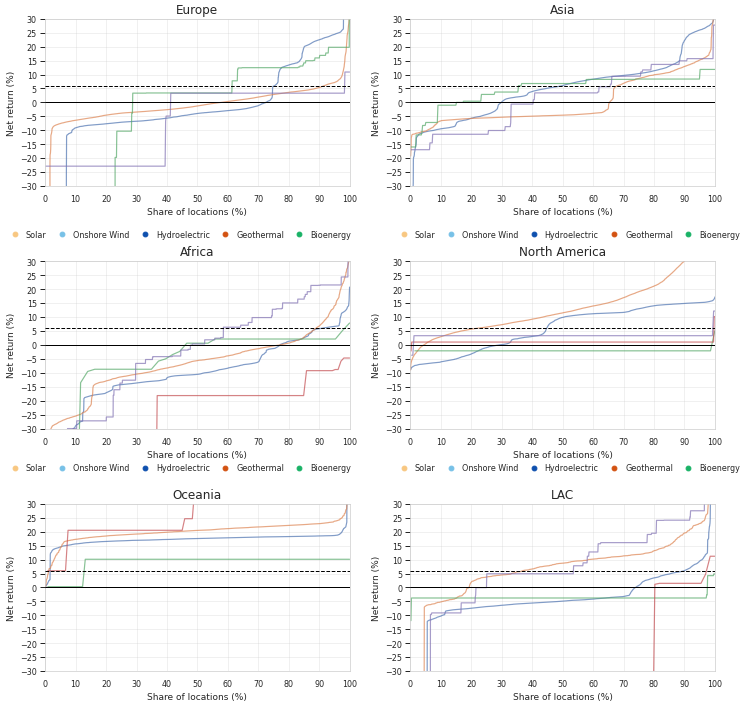

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from math import ceil
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon

def plot_coc_vs_ror_from_gridded_ds(
    ds,
    region_var="region",                  # 2D variable (lat, lon)
    tech_var="Cheapest_Technology",       # 2D variable (lat, lon)
    x_var="Estimated_WACC",               # x = rate of return proxy
    y_var="Calculated_LCOE",              # y = cost of capital proxy (set what you want)
    regions=None,                         # None => all unique non-null regions
    technologies=None,                    # None => all unique non-null technologies
    tech_colors=None,
    ncols=2,
    figsize_per_colrow=(6, 4),
    alpha=0.7,
    s=8,
    figure_title="Y vs X by Region (colored by technology)",  # kept arg, not used
    x_label="Share of locations (%)",
    y_label="Net return (%)",
    region_order=["Europe", "Asia", "Africa", "North America", "South America and the Caribbean", "Oceania"],
    sharex=True,
    sharey=True,
    grid=False,
):
    # Flatten arrays once
    r = ds[region_var].values.ravel()
    t = ds[tech_var].values.ravel()
    x = ds[x_var].values.ravel()
    y = ds[y_var].values.ravel()

    # Keep finite x/y
    base_mask = np.isfinite(x) & np.isfinite(y)

    # region/tech valid mask (not nan/None/"")
    r_valid = np.array([vv is not None and str(vv) != "nan" and str(vv).strip() != "" for vv in r])
    t_valid = np.array([vv is not None and str(vv) != "nan" and str(vv).strip() != "" for vv in t])

    mask = base_mask & r_valid & t_valid
    r, t, x, y = r[mask], t[mask], x[mask], y[mask]

    if regions is None:
        regions = np.unique(r).tolist()

    # Apply explicit ordering if provided
    if region_order is not None:
        # keep only regions that exist in data (and avoid duplicates)
        existing = set(regions)
        ordered = []
        for reg in region_order:
            if reg in existing and reg not in ordered:
                ordered.append(reg)

        # append any remaining regions not listed (optional behavior)
        remaining = [reg for reg in regions if reg not in ordered]
        regions = ordered + remaining
    if technologies is None:
        technologies = np.unique(t).tolist()

    if len(regions) == 0:
        raise ValueError("No valid regions found. Your 'region' variable appears empty/all-NaN.")

    if tech_colors is None:
        cmap = plt.get_cmap("tab10")
        tech_colors = {tech: cmap(i % 10) for i, tech in enumerate(technologies)}

    n_regions = len(regions)
    ncols = min(ncols, n_regions)
    nrows = ceil(n_regions / ncols)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_colrow[0]*ncols, figsize_per_colrow[1]*nrows),
        sharex=sharex, sharey=sharey
    )
    axes = np.atleast_1d(axes).ravel()

    for i, region in enumerate(regions):
        ax = axes[i]
        reg_mask = (r == region)
        
        for tech in technologies:
            m = reg_mask & (t == tech)
            if np.any(m):
                selected_values = y[m]
                total_values = len(selected_values)
                x_population_share = np.linspace(1 / total_values, 1, total_values)
                selected_values.sort()
                ax.plot(x_population_share*100, selected_values, alpha=alpha)

        # Keep region labels (not removed by your request)
        ax.set_title(str(region))

        # Show labels on EVERY subplot
        ax.set_xlabel(x_label)
        ax.set_ylabel(y_label)

        if grid:
            ax.grid(True, alpha=0.25)

    for j in range(n_regions, len(axes)):
        axes[j].set_visible(False)

    yticks = np.arange(-30, 35, 5)
    xticks = np.arange(0, 110, 10)

    for ax in axes[:n_regions]:
        ax.set_xticks(xticks)
        ax.set_yticks(yticks)

        # force tick labels visible on all shared axes
        ax.tick_params(axis="x", which="both", labelbottom=True)
        ax.tick_params(axis="y", which="both", labelleft=True)

        # x-limits symmetric around zero using y max
        ymin, ymax = ax.get_ylim()
        ax.set_xlim([0, 100])
        ax.set_ylim([-30, 30])
        xmin, xmax = ax.get_xlim()
        # Remove internal padding so data/patch reaches axes bounds
        ax.margins(x=0, y=0)


        # --- Move y-axis to center (x=0) but keep full box ---
        ax.spines["left"].set_position(("data", 0))   # centered y-axis
        ax.yaxis.set_ticks_position("left")
        ax.yaxis.set_label_position("left")

        # keep rectangular box visible
        for side in ["top", "right", "bottom"]:
            ax.spines[side].set_visible(True)

        # draw left border too (since left spine moved to x=0)
        ax.plot([0, 100], [0, 0], color="black", lw=1.0, zorder=3)
        
        # Draw horizontal line at y = hurdle rate
        ax.axhline(y=hurdle_rate, color="black", lw=1.0, zorder=3, linestyle="--")

    # No global title/xlabel/ylabel (per your request to remove title and show per plot labels)

    # Legend
    handles = [
        Line2D([0], [0], marker='o', linestyle='', color=tech_colors[k], label=str(k))
        for k in technologies
    ]

    # 4 legends: 2 columns × 2 gaps (for a 3x2 grid)
    x_positions = [0.28, 0.73]   # centers of left and right columns
    y_positions = [0.63, 0.36] # between row1-row2, and row2-row3

    for y_pos in y_positions:
        for x_pos in x_positions:
            fig.legend(
                handles=handles,
                loc="center",
                bbox_to_anchor=(x_pos, y_pos),
                ncol=5,
                frameon=False,
                fontsize=8,
                columnspacing=0.9,
                handletextpad=0.4
            )

    plt.rcParams["axes.xmargin"] = 0
    plt.rcParams["axes.ymargin"] = 0
    #plt.tight_layout()
    fig.subplots_adjust(hspace=0.45)
    return fig, axes

# Example: custom colors and subset selection
tech_palette = {
    "Solar":          "#F8C781",  # warm yellow-orange, hue ~35
    "Onshore Wind":   "#77C1E7",  # light sky blue
    "Bioenergy":      "#19B266",  # green
    "Geothermal":     "#D35211",  # deep orange / vermillion (heat)
    "Hydroelectric":  "#0E50AE",  # dark blue (water)
}
hurdle_rate = 6
results["IRR_net"] = results["Benchmark_IRR"] - results["Estimated_WACC"]
fig, axes = plot_coc_vs_ror_from_gridded_ds(
    ds=results,
    region_var="region",
    tech_var="Cheapest_Technology",
    x_var="abatement_MW",
    y_var="IRR_net",   # or whichever y you intend
    regions=None,              # all unique regions
    tech_colors=tech_palette,
    technologies=["Solar", "Onshore Wind", "Hydroelectric", "Geothermal", "Bioenergy"]
)
plt.savefig("./OUTPUT_FOLDER_REAL_INPUT/IRR_by_regionCHECK.png")
plt.show()

In [76]:
import pandas as pd
import re
def q75(x):
    return x.quantile(0.75)
def q90(x):
    return x.quantile(0.90)

def q25(x):
    return x.quantile(0.25)

def extract_generation_by_technology(results, ember_data, country_mapping, years=None):
    """
    Build country-level panel with yearly capacity columns for each renewable technology + total Renewables.
    Output columns like:
      WIND_2020, SOLAR_2020, HYDRO_2020, BIOENERGY_2020, OTHER_RENEWABLE_2020, RENEWABLES_2020, ...
    """
    if years is None:
        years = sorted(ember_data["Year"].dropna().unique().astype(int).tolist())

    tech_map = {
        "Wind": "WIND",
        "Solar": "SOLAR",
        "Hydro": "HYDRO",
        "Bioenergy": "BIOENERGY",
        "Other Renewables": "OTHER_RENEWABLE",
        "Renewables": "RENEWABLES"
    }

    merged_data = None

    for year in years:
        year_df = ember_data.loc[
            (ember_data["Unit"] == "GW") &
            (ember_data["Year"] == year) &
            (ember_data["Variable"].isin(tech_map.keys()))
        ][["Country code", "Variable", "Value"]].copy()

        # Pivot so each technology is a column
        year_wide = year_df.pivot_table(
            index="Country code",
            columns="Variable",
            values="Value",
            aggfunc="sum"
        ).reset_index()

        # Rename columns to TECH_YEAR format
        rename_dict = {}
        for k, v in tech_map.items():
            if k in year_wide.columns:
                rename_dict[k] = f"{v}_{year}"
        year_wide = year_wide.rename(columns=rename_dict)

        # Ensure all expected columns exist
        for v in tech_map.values():
            col = f"{v}_{year}"
            if col not in year_wide.columns:
                year_wide[col] = pd.NA

        keep_cols = ["Country code"] + [f"{v}_{year}" for v in tech_map.values()]
        year_wide = year_wide[keep_cols]

        if merged_data is None:
            merged_data = year_wide.copy()
        else:
            merged_data = merged_data.merge(year_wide, how="outer", on="Country code")

    # map country names
    gen_data_mapping = pd.merge(country_mapping, merged_data, how="left", on="Country code")
    gen_data_mapping = gen_data_mapping.rename(columns={"index": "Country"})

    # collapse results to country level (same pattern as your current function)
    results_df = results.to_dataframe()
    results_df_grouped = results_df.groupby(["Country"]).agg({
        "Calculated_LCOE":  q25,
        "Estimated_WACC": "median",
        "Benchmark_IRR": q75,
        "IRR_net_": "mean"
    }).reset_index()

    # join generation panel
    results_df_grouped = results_df_grouped.merge(gen_data_mapping, how="left", on="Country")
    return results_df_grouped


def fill_from_left_for_prefixes(df, prefixes, years=None, inplace=False):
    """
    Progressive left->right fill for multiple prefix families, e.g. WIND_, SOLAR_, ...
    """
    out = df if inplace else df.copy()

    for prefix in prefixes:
        if years is None:
            pattern = re.compile(rf"^{re.escape(prefix)}(\d{{4}})$")
            year_cols = []
            for c in out.columns:
                m = pattern.match(c)
                if m:
                    year_cols.append((int(m.group(1)), c))
            year_cols = [c for _, c in sorted(year_cols)]
        else:
            year_cols = [f"{prefix}{y}" for y in years if f"{prefix}{y}" in out.columns]

        for i in range(1, len(year_cols)):
            left_col = year_cols[i - 1]
            cur_col = year_cols[i]
            out[cur_col] = out[cur_col].fillna(out[left_col])

    return out


def calculate_investment_by_technology(
    df,
    cost_data,
    country_col="Country",
    tech_prefixes=None,
    start_year=None,
    end_year=None,
    capacity_unit="GW",
    cost_unit="USD_per_kW",
    clip_negative_additions=True
):
    """
    Compute annual and total investment using technology-specific additions and costs.

    cost_data expected long format:
      Year, Technology, Cost
    where Technology values match tech names after normalization:
      WIND, SOLAR, HYDRO, BIOENERGY, OTHER_RENEWABLE
    """
    if tech_prefixes is None:
        tech_prefixes = ["WIND", "SOLAR", "HYDRO", "BIOENERGY", "OTHER_RENEWABLE"]

    # Infer year range from dataframe columns
    all_years = set()
    for col in df.columns:
        m = re.match(r"^[A-Z_]+_(\d{4})$", col)
        if m:
            all_years.add(int(m.group(1)))
    all_years = sorted(all_years)

    if not all_years:
        raise ValueError("No year columns found in dataframe.")

    if start_year is None:
        start_year = min(all_years)
    if end_year is None:
        end_year = max(all_years)

    years = [y for y in all_years if start_year <= y <= end_year]
    if len(years) < 2:
        raise ValueError("Need at least two years to compute additions.")

    # Prepare costs
    c = cost_data.copy()
    c.columns = [x.strip() for x in c.columns]
    required = {"Year", "Technology", "Cost"}
    if not required.issubset(set(c.columns)):
        raise ValueError(f"cost_data must contain columns {required}")

    c["Year"] = c["Year"].astype(int)
    c["Technology"] = (
        c["Technology"].str.strip().str.upper()
         .str.replace(" ", "_", regex=False)
    )

    # Convert costs to USD/GW
    c["Cost_USD_per_GW"] = c["Cost"] * 1_000_000

    # Capacity conversion to GW
    if capacity_unit == "GW":
        cap_to_gw = 1.0
    elif capacity_unit == "MW":
        cap_to_gw = 1 / 1000.0
    elif capacity_unit == "kW":
        cap_to_gw = 1 / 1_000_000.0
    else:
        raise ValueError("capacity_unit must be GW, MW, or kW")

    annual_records = []

    for tech in tech_prefixes:
        for i in range(1, len(years)):
            y_prev = years[i - 1]
            y_curr = years[i]
            prev_col = f"{tech}_{y_prev}"
            curr_col = f"{tech}_{y_curr}"

            if prev_col not in df.columns or curr_col not in df.columns:
                continue

            tmp = df[[country_col, prev_col, curr_col]].copy()
            tmp = tmp.rename(columns={prev_col: "Cap_prev", curr_col: "Cap_curr"})
            tmp["Year"] = y_curr
            tmp["Technology"] = tech

            tmp["Addition"] = tmp["Cap_curr"] - tmp["Cap_prev"]
            if clip_negative_additions:
                tmp["Addition"] = tmp["Addition"].clip(lower=0)

            tmp["Addition_GW"] = tmp["Addition"] * cap_to_gw
            annual_records.append(tmp[[country_col, "Year", "Technology", "Addition_GW"]])

    annual = pd.concat(annual_records, ignore_index=True)

    # Merge costs
    annual = annual.merge(
        c[["Year", "Technology", "Cost_USD_per_GW"]],
        how="left",
        on=["Year", "Technology"]
    )

    if annual["Cost_USD_per_GW"].isna().any():
        missing = annual.loc[annual["Cost_USD_per_GW"].isna(), ["Year", "Technology"]].drop_duplicates()
        raise ValueError(f"Missing cost entries for:\n{missing}")

    annual["Investment_USD"] = annual["Addition_GW"] * annual["Cost_USD_per_GW"]

    # Totals
    totals_country_year = (
        annual.groupby([country_col, "Year"], as_index=False)["Investment_USD"].sum()
        .rename(columns={"Investment_USD": "Investment_USD_all_tech"})
    )

    totals_country = (
        annual.groupby([country_col], as_index=False)["Investment_USD"].sum()
        .rename(columns={"Investment_USD": "Total_Investment_USD"})
    )

    totals_tech_country = (
        annual.groupby([country_col, "Technology"], as_index=False)["Investment_USD"].sum()
        .rename(columns={"Investment_USD": "Total_Investment_USD"})
    )

    return annual, totals_country_year, totals_country, totals_tech_country


ember_data = pd.read_csv("./DATA/Ember Yearly Data 2026.csv")
country_mapping = pd.read_csv("./DATA/country_mapping.csv")
region_mapping = pd.read_csv(
    "/Users/lukehatton/Documents/Imperial PhD/Analysis/LCOE Concessional Model/DATA/country_mapping_regions.csv",
    encoding="cp1252"
)

# 1) Extract tech-level capacities
results_df_new = extract_generation_by_technology(results, ember_data, country_mapping, years=[2019, 2020, 2021, 2022, 2023, 2024, 2025])

# 2) Merge region mapping
results_df_new = results_df_new.merge(
    region_mapping[["index", "region"]],
    how="left",
    right_on="index",
    left_on="Country",
    suffixes=("", "_duplicate")
)

# 3) Fill missing yearly capacity values progressively within each technology
results_df_new = fill_from_left_for_prefixes(
    results_df_new,
    prefixes=["WIND_", "SOLAR_", "HYDRO_", "BIOENERGY_", "OTHER_RENEWABLE_", "RENEWABLES_"],
    years=[2020, 2021, 2022, 2023, 2024, 2025]
)

# 4) Read technology-specific cost table (long format: Year, Technology, Cost)
cost_data = pd.read_excel("./DATA/IRENA_TIC_Timeseries.xlsx")
cost_data.columns = cost_data.columns.astype(str)
cost_data = cost_data.melt(id_vars="Technology", value_name="Cost", var_name="Year")
cost_data["Technology"] = cost_data["Technology"].map({
        "Wind": "WIND",
        "Solar": "SOLAR",
        "Hydro": "HYDRO",
        "Bioenergy": "BIOENERGY",
        "Other Renewables": "OTHER_RENEWABLE",
    })
annual, totals_country_year, totals_country, totals_tech_country = calculate_investment_by_technology(
    df=results_df_new,
    cost_data=cost_data,
    country_col="Country",
    tech_prefixes=["WIND", "SOLAR", "HYDRO", "BIOENERGY", "OTHER_RENEWABLE"],
    start_year=2020,
    end_year=2024,
    capacity_unit="GW",
    cost_unit="USD_per_kW",  # change if needed
    clip_negative_additions=True
)

# Optional: merge total investment back
results_df_with_investment = results_df_new.merge(totals_country, how="left", on="Country")
results_df_with_investment['REN_diff'] = results_df_with_investment["RENEWABLES_2025"] - results_df_with_investment["RENEWABLES_2020"]

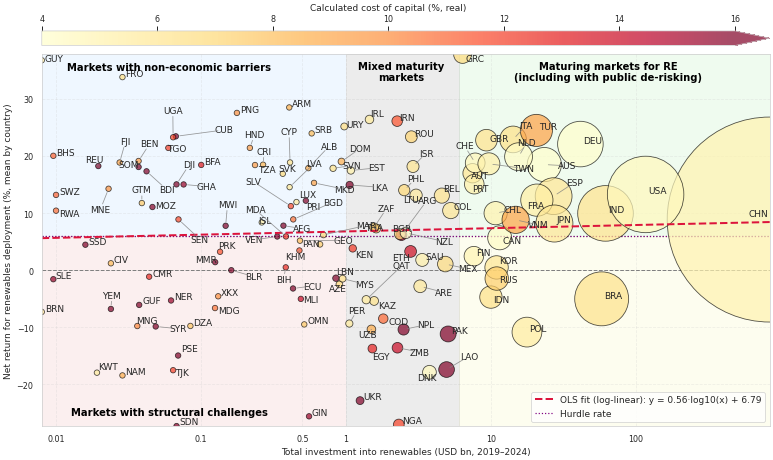

In [77]:

import numpy as np
import matplotlib.pyplot as plt
from adjustText import adjust_text
from matplotlib.patches import Rectangle

def plot_region_bubbles(
    df,
    x_col='Total_Investment_USD',
    y_col='IRR_net_',
    size_col='Calculated_LCOE',
    region_col='Country code',
    col_col="Estimated_WACC",
    size_scale=50,
    min_size=30,
    label_min_x=0.001,
    # --- new quadrant parameters ---
    x_split=None,   # e.g. 10 (GW increase)
    y_split=None,   # e.g. 0 (0% net return)
    quadrant_labels=None,
    quadrant_colors=None,
    output_path="./OUTPUT_FOLDER_REAL_INPUT/IRR_vs_RENdiff_GLOBAL.png"
):
    data = df.copy()
    
    # Convert total investment into USD bn
    data['Total_Investment_USD'] = data['Total_Investment_USD'] / 1e+09
    # Keep only valid rows for plotting
    plot_data = data[[region_col, 'Total_Investment_USD', y_col, size_col, col_col]].dropna().copy()
    plot_data = plot_data[plot_data['Total_Investment_USD'] > 0]
    plot_data = plot_data[(plot_data[y_col] > -40) & (plot_data[y_col] < 40)]

    fig, ax = plt.subplots(figsize=(11, 7))

    # -------------------------
    # Quadrant shading (background)
    # -------------------------
    # Determine axis limits first (before scatter) to define rectangles
    x_min = plot_data['Total_Investment_USD'].min()
    x_max = plot_data['Total_Investment_USD'].max()
    y_min = plot_data[y_col].min()
    y_max = plot_data[y_col].max()

    # If not provided, choose defaults:
    # - x_split: geometric mean of x-range (midpoint in log space)
    # - y_split: 0 (break-even IRR)
    if x_split is None:
        x_split = np.sqrt(x_min * x_max)  # mid in log-space
    if y_split is None:
        y_split = 0.0

    # Default labels if not provided
    if quadrant_labels is None:
        quadrant_labels = {
            "Q1": "High RE growth\nHigh net return",
            "Q2": "Low RE growth\nHigh net return",
            "Q3": "Low RE growth\nLow net return",
            "Q4": "High RE growth\nLow net return",
        }

    # Default colors (very light, not to clash with data)
    if quadrant_colors is None:
        quadrant_colors = {
            "Q1": (0.8, 0.95, 0.8, 0.3),   # light green
            "Q2": (0.8, 0.9, 1.0, 0.3),    # light blue
            "Q3": (0.95, 0.8, 0.8, 0.3),   # light red
            "Q4": (0.98, 0.98, 0.8, 0.3),  # light yellow
        }
        
     # Soft transition around x_split (log-aware)
    f = 1.2  # width factor; try 1.3 to 2.0
    x_left = 1
    x_right = x_split * f

    # Keep inside plotting range
    x_left = max(x_left, x_min)
    x_right = min(x_right, x_max)

    # LEFT blocks
    rect_Q2 = Rectangle(
        (x_min, y_split),
        x_left - x_min,
        y_max - y_split,
        facecolor=quadrant_colors["Q2"],
        edgecolor='none',
        zorder=0
    )
    rect_Q3 = Rectangle(
        (x_min, y_min),
        x_left - x_min,
        y_split - y_min,
        facecolor=quadrant_colors["Q3"],
        edgecolor='none',
        zorder=0
    )

    # RIGHT blocks
    rect_Q1 = Rectangle(
        (x_right, y_split),
        x_max - x_right,
        y_max - y_split,
        facecolor=quadrant_colors["Q1"],
        edgecolor='none',
        zorder=0
    )
    rect_Q4 = Rectangle(
        (x_right, y_min),
        x_max - x_right,
        y_split - y_min,
        facecolor=quadrant_colors["Q4"],
        edgecolor='none',
        zorder=0
    )

    for rect in [rect_Q1, rect_Q2, rect_Q3, rect_Q4]:
        ax.add_patch(rect)

    # -------------------------
    # Scatter plot
    # -------------------------
    sizes = (plot_data['Total_Investment_USD'] * size_scale).clip(lower=min_size)

    sc = ax.scatter(
        plot_data['Total_Investment_USD'],
        plot_data[y_col],
        s=sizes,
        c=plot_data[col_col],
        alpha=0.7,
        edgecolors='black',
        cmap="YlOrRd",
        linewidth=0.8,
        vmax=16,
        vmin=4,
        zorder=2
    )

    ax.set_xscale("log")
    ticks = [0.01, 0.1, 0.5, 1, 10, 100, 1000]
    ax.set_xticks(ticks, labels=[str(x) for x in ticks])

    # Best-fit line: y ~ log10(x)
    x = plot_data['Total_Investment_USD'].to_numpy()
    y = plot_data[y_col].to_numpy()


    if len(x) >= 2:
        X = np.log10(x)
        m, b = np.polyfit(X, y, 1)  # y = m*log10(x) + b

        x_line = np.logspace(np.log10(x.min()), np.log10(x.max()), 200)
        y_line = m * np.log10(x_line) + b

        fit_label = f"OLS fit (log-linear): y = {m:.2f}·log10(x) + {b:.2f}"

        ax.plot(
            x_line, y_line,
            color='crimson',
            linewidth=2.0,
            linestyle='--',
            label=fit_label,
        )


    # Labels only above threshold
    texts = []
    label_data = plot_data[plot_data['Total_Investment_USD'] > label_min_x]
    for _, row in label_data.iterrows():
        txt = ax.text(
            row['Total_Investment_USD'],
            row[y_col],
            str(row[region_col]),
            fontsize=9,
            zorder=3
        )
        texts.append(txt)

    if texts:
        adjust_text(
            texts,
            ax=ax,
            force_text=(0.8, 2.5),
            force_points=(4, 8),
            expand_text=(100, 150),
            expand_points=(1500, 2500),
            lim=1000,
            arrowprops=dict(
                arrowstyle='-',
                color='gray',
                lw=0.8,
                alpha=0.8,
                shrinkA=6,
                shrinkB=4
            )
        )

    # Colorbar
    cbar = fig.colorbar(
        sc,
        ax=ax,
        orientation='horizontal',
        pad=0.02,
        location='top',
        aspect=50,
        extend="max",
        cmap="YlOrRd"
    )
    cbar.set_label('Calculated cost of capital (%, real)')

    # Axes lines and labels
    ax.axhline(0, color='gray', linestyle='--', linewidth=1, zorder=1)
    ax.set_xlabel("Total investment into renewables (USD bn, 2019–2024)")
    ax.set_ylabel("Net return for renewables deployment (%, mean by country)")
    ax.grid(True, linestyle='--', alpha=0.3, zorder=1)

    # Draw the quadrant boundary lines on top of shading
    #ax.axvline(x_split, color='gray', linestyle=':', linewidth=1.2, zorder=1.5)
    ax.axhline(y_split, color='gray', linestyle=':', linewidth=1.2, zorder=1.5)
    
   

    # Draw transition band
    ax.axvspan(
        x_left, x_right,
        color="grey",
        alpha=0.15,
        zorder=1.2
    )

    # Optional dashed guide at nominal split
    #ax.axvline(x_split, color='gray', linestyle=':', linewidth=1.0, alpha=0.7, zorder=1.5)

    # Keep horizontal split
    ax.axhline(y_split, color='purple', linestyle=':', linewidth=1.2, zorder=1.5, label="Hurdle rate")
    ax.legend(loc='lower right', fontsize=9)


    # Quadrant labels (place them roughly in the center of each quadrant)
    ax.text(
        np.sqrt(x_split * x_max),  # mid in log-space for right side
        0.92*y_max,
        quadrant_labels["Q1"],
        ha='center',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='black',
        zorder=4
    )
    ax.text(
        0.06,  # mid in log-space for left side
        0.94*y_max,
        quadrant_labels["Q2"],
        ha='center',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='black',
        zorder=4
    )
    ax.text(
        0.06 ,
        y_min + 2.5,
        quadrant_labels["Q3"],
        ha='center',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='black',
        zorder=4
    )
    ax.text(
        2.4,
        0.92*y_max,
        quadrant_labels["Q5"],
        ha='center',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='black',
        zorder=4
    )

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    
quadrant_labels = {
    "Q1": "Maturing markets for RE\n(including with public de-risking)",
    "Q2": "Markets with non-economic barriers",
    "Q3": "Markets with structural challenges",
    "Q4": "Markets with strong public sector de-risking",
    "Q5": "Mixed maturity\nmarkets"
}

plot_region_bubbles(
    results_df_with_investment,
    x_split=5.0,      # e.g. 5 GW increase
    y_split=6.0,      # 0% net return
    quadrant_labels=quadrant_labels,
    output_path="./OUTPUT_FOLDER_REAL_INPUT/IRR_vs_RENdiff_GLOBAL_quadrantsCHECK.png"
)


results_df_with_investment.to_csv("CountryLevelResults.csv")

In [118]:
results_df_with_investment["REN_diff"] = results_df_with_investment["RENEWABLES_2024"] - results_df_with_investment["RENEWABLES_2019"]
country_agg_df = results_df_with_investment.copy()
extract = country_agg_df.loc[country_agg_df["Country code"].isin(["CHN", "DEU", "USA", "IND", "JPN", "AUS"])].sort_values(by="IRR_net_")
print(extract["REN_diff"].sum())
print(results_df_with_investment["REN_diff"].sum())
print(extract["REN_diff"].sum() / results_df_with_investment["REN_diff"].sum())
country_agg_df.sort_values(by="REN_diff", ascending=False).head(10)

1421.3599999999997
1894.9099999999996
0.750093671994976


,Country,Calculated_LCOE,Estimated_WACC,Benchmark_IRR,IRR_net_,Country code,Region,name,region,sub-region,...,WIND_2025,SOLAR_2025,HYDRO_2025,BIOENERGY_2025,OTHER_RENEWABLE_2025,RENEWABLES_2025,index,region_duplicate,Total_Investment_USD,REN_diff
33,47.0,30.066875,5.154437,16.212568,11.058131,CHN,CHN,China,Asia,Eastern Asia,...,521.75,887.93,385.00,19.14,NaN,1813.82,47,Asia,8.403271e+11,1060.99
172,232.0,50.317851,4.687127,21.611095,16.923968,USA,USA,United States of America,North America,Northern America,...,153.15,177.47,84.17,9.98,3.63,428.40,232,North America,1.169465e+11,164.57
78,104.0,33.467686,6.358532,16.740433,10.381901,IND,IND,India,Asia,Southern Asia,...,48.16,97.38,47.51,10.93,NaN,203.98,104,Asia,6.183191e+10,75.67
19,30.0,37.753921,6.429616,3.659736,-3.962598,BRA,CSA,Brazil,LAC,LAC,...,32.96,53.11,109.98,17.79,NaN,213.84,30,LAC,5.818079e+10,69.23
39,56.0,41.300740,4.159965,26.887214,22.727248,DEU,WEU,Germany,Europe,Western Europe,...,0.00,0.00,0.00,0.00,0.00,0.00,56,Europe,4.148886e+10,55.01
50,67.0,52.466238,6.100074,19.828685,13.728611,ESP,WEU,Spain,Europe,Southern Europe,...,0.00,0.00,0.00,0.00,0.00,0.00,67,Europe,2.710679e+10,33.86
85,113.0,43.206217,6.098063,14.319919,8.221855,JPN,JPN,Japan,Asia,Eastern Asia,...,5.83,91.61,28.19,5.13,NaN,130.76,113,Asia,2.744092e+10,33.53
7,12.0,43.350799,4.163216,24.235505,20.072290,AUS,AUS,Australia,Oceania,Australia and New Zealand,...,15.29,38.47,8.79,0.94,NaN,63.49,12,Oceania,2.337762e+10,31.59
166,224.0,50.136580,9.357098,35.159151,25.802053,TUR,MEA,Turkey,Asia,Western Asia,...,0.00,0.00,0.00,0.00,0.00,0.00,224,Asia,2.061280e+10,24.60
121,165.0,47.060858,4.396736,24.889082,20.492347,NLD,WEU,Netherlands,Europe,Western Europe,...,0.00,0.00,0.00,0.00,0.00,0.00,165,Europe,1.552454e+10,24.09


In [61]:
results_df_new[["region", "IRR_net_"]].groupby("region").agg("median").reset_index()


,region,IRR_net_
0,Asia,0.043017
1,Europe,15.052437
2,LAC,10.854385
3,North Africa,-12.952205
4,North America,16.923968
5,Oceania,48.051177
6,Sub-Saharan Africa,4.721677
7,Unclassified,-7.467286


/Users/lukehatton/opt/anaconda3/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: The following kwargs were not used by contour: 'edgecolor'
  result = super().contourf(*args, **kwargs)


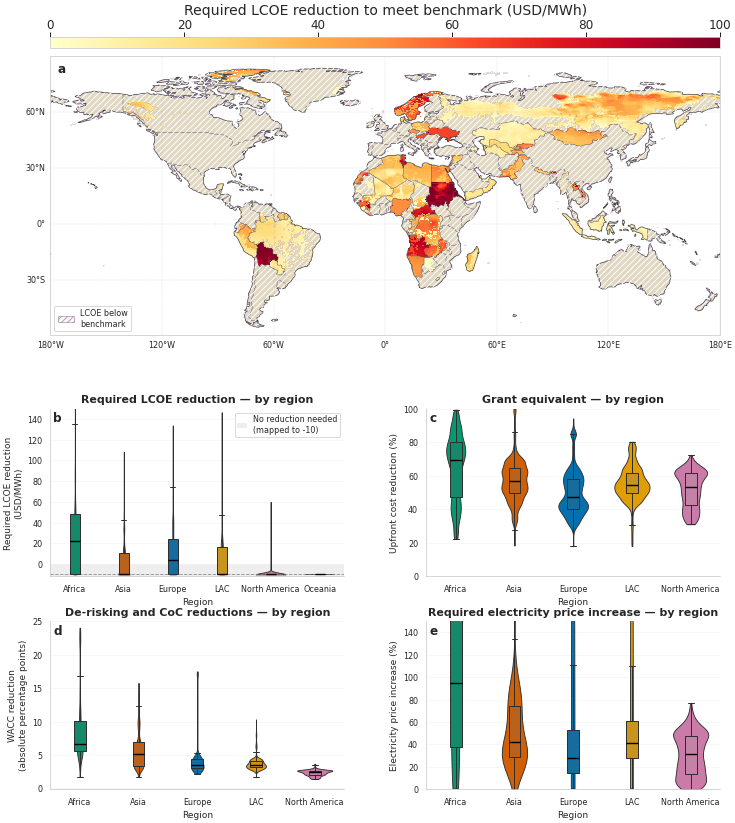

82.38969917932582
     status  WACC_Reductions
0  Advanced         1.495995
1     China         0.112155
2      EMDE         4.566164
     status  Electricity_Price_Increase
0  Advanced                   53.686434
1      EMDE                   41.711455
     status  Grant_Equivalent_%
0  Advanced            0.293673
1     China            0.022115
2      EMDE            0.450819
     status  Financing_Gap
0  Advanced      36.201814
1      EMDE      30.271778
159.24965307740234


In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

# -----------------------------
# Styling for publication
# -----------------------------
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "savefig.dpi": 600,
})

# Colorblind-safe, journal-friendly palette
REGIONAL_PALETTE = "colorblind"

def _style_map_axis(ax, extent):
    ax.coastlines(linewidth=0.7, color="#404040")
    ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="#606060")
    ax.set_extent(extent, crs=ccrs.PlateCarree())

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=0.35,
        color="gray",
        alpha=0.35,
        linestyle="--"
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.bottom_labels = True
    gl.left_labels = True

    # 60° in longitude and 30° in latitude
    gl.xlocator = mticker.FixedLocator([-180, -120, -60, 0, 60, 120, 180])
    gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {"size": 8}
    gl.ylabel_style = {"size": 8}

def _add_top_colorbar(fig, ax, mesh, label, fontsize=14):
    cax = ax.inset_axes([0.0, 1.03, 1.0, 0.04])
    cbar = fig.colorbar(mesh, cax=cax, orientation="horizontal")
    cbar.set_label(label, fontsize=fontsize, labelpad=4)
    cbar.ax.xaxis.set_ticks_position("top")
    cbar.ax.xaxis.set_label_position("top")
    cbar.ax.tick_params(labelsize=12, pad=1)
    return cbar

def _to_regional_df(ds, var_name, region_name="Region", mask=None):
    da = ds[var_name]
    if mask is not None:
        da = da.where(mask)

    region = ds[region_name]
    if set(region.dims) != set(da.dims):
        region = region.broadcast_like(da)

    df = pd.DataFrame({
        "region": region.values.ravel(),
        "value": da.values.ravel()
    })

    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=["region", "value"])
    return df

def plot_map_and_regional_distributions_map_top_2x2(
    ds,
    region_name="region",
    lon_name="longitude",
    lat_name="latitude",
    mask_num_var="Calculated_LCOE",
    mask_den_var="Benchmark_LCOE",
    extent=(-180, 180, -60, 90),
    figsize=(12, 14),
    output_path=None
):
    ds = ds.copy()

    keep_mask = ds[mask_num_var] >= ds[mask_den_var]
    shade_mask = (ds[mask_num_var] < ds[mask_den_var]).values.astype(float)
    req_reduction_usd = (ds[mask_num_var] - ds[mask_den_var]).clip(min=0)

    # Include all valid locations:
    # - positive reductions keep their value
    # - no reduction needed gets sentinel (e.g., -5)
    no_need_value = -10.0

    req_reduction_with_floor = xr.where(
        np.isfinite(req_reduction_usd),
        xr.where(req_reduction_usd > 0, req_reduction_usd, no_need_value),
        np.nan
    )

    df_lcoe = _to_regional_df(
        ds.assign(Required_LCOE_Reduction=req_reduction_with_floor),
        "Required_LCOE_Reduction",
        region_name=region_name,
        mask=np.isfinite(req_reduction_with_floor)
    )
    df_cost = _to_regional_df(ds, "Grant_Equivalent_%", region_name=region_name, mask=keep_mask)
    df_cost["value"] = df_cost["value"] * 100
    df_wacc = _to_regional_df(ds, "WACC_Reductions", region_name=region_name, mask=keep_mask)
    df_price = _to_regional_df(ds, "Electricity_Price_Increase", region_name=region_name, mask=keep_mask)

    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(
        nrows=3, ncols=2,
        height_ratios=[3, 1.5, 1.5],
        hspace=0.20, wspace=0.28
    )

    # -------------------------
    # Map panel
    # -------------------------
    ax_map = fig.add_subplot(gs[0, :], projection=ccrs.PlateCarree())

    mesh = ax_map.pcolormesh(
        ds[lon_name], ds[lat_name], req_reduction_usd.values,
        transform=ccrs.PlateCarree(),
        cmap="YlOrRd",
        vmin=0, vmax=100,
        shading="auto"
    )

    # Hatched + translucent shading where Calculated_LCOE < Benchmark
    ax_map.contourf(
        ds[lon_name], ds[lat_name], shade_mask,
        levels=[0.5, 1.5],
        hatches=["////"],
        colors="none",              # hatch-only layer (no fill)
        edgecolor="#3b1f5e",        # hatch line color
        transform=ccrs.PlateCarree(),
        zorder=3
    )

    # Translucent fill layer underneath
    ax_map.contourf(
        ds[lon_name], ds[lat_name], shade_mask,
        levels=[0.5, 1.5],
        colors=["#6a3d9a"],
        alpha=0.2,
        transform=ccrs.PlateCarree(),
        zorder=2.8
    )

    _style_map_axis(ax_map, extent)
    _add_top_colorbar(
        fig, ax_map, mesh,
        "Required LCOE reduction to meet benchmark (USD/MWh)",
    )

    # Legend for hatched shading
    shaded_patch = mpatches.Patch(
        facecolor="cornsilk",
        edgecolor="#6a3d9a",
        hatch="////",
        alpha=0.5,
        label="LCOE below\nbenchmark"
    )
    ax_map.legend(
        handles=[shaded_patch],
        loc="lower left",
        frameon=True,
        framealpha=0.95,
        title_fontsize=8,
        fontsize=8
    )

    # -------------------------
    # Improved violin helper
    # -------------------------
    def _violin(ax, df, ylabel, title, ylim=None):
        
        region_color_map = {
            "Africa": "#009E73",         # bluish green
            "Asia": "#D55E00",           # vermillion
            "Europe": "#0072B2",         # blue
            "North America": "#CC79A7",  # reddish purple
            "LAC": "#E69F00",            # orange
            "Oceania": "#56B4E9",        # sky blue
        }
        if df.empty:
            ax.text(0.5, 0.5, "No valid data", ha="center", va="center", transform=ax.transAxes)
            ax.set_ylabel(ylabel)
            ax.set_title(title, fontsize=11, fontweight="bold")
            ax.set_xticks([])
            return

        region_order = sorted(df["region"].unique())
        palette = [region_color_map[r] for r in region_order]

        # Violin layer
        sns.violinplot(
            data=df,
            x="region", y="value",
            order=region_order,
            palette=palette,
            inner=None,
            cut=0,
            width=0.6,
            linewidth=0.9,
            saturation=0.95,
            ax=ax
        )

        # Boxplot overlay (colored, not white)
        bp = sns.boxplot(
            data=df,
            x="region", y="value",
            order=region_order,
            width=0.20,
            showcaps=True,
            showfliers=False,
            palette=palette,  # same region colors
            boxprops={"linewidth": 1.0, "zorder": 3},
            medianprops={"color": "black", "linewidth": 1.4, "zorder": 3},
            whiskerprops={"color": "#2f2f2f", "linewidth": 1.0},
            capprops={"color": "#2f2f2f", "linewidth": 1.0},
            ax=ax
        )

        # Darken box edges for contrast
        for patch in ax.artists:
            patch.set_alpha(0.95)
            patch.set_edgecolor("#303030")
            patch.set_linewidth(1.0)

        ax.set_ylabel(ylabel)
        ax.set_xlabel("Region")
        ax.set_title(title, fontsize=11, fontweight="bold")
        ax.tick_params(axis="x")
        ax.grid(axis="y", alpha=0.25, linewidth=0.6)
        ax.grid(axis="x", visible=False)
        sns.despine(ax=ax, top=True, right=True)

        if ylim is not None:
            ax.set_ylim(ylim)

    # Row 1
    ax21 = fig.add_subplot(gs[1, 0])
    _violin(
    ax21,
    df_lcoe,
    "Required LCOE reduction\n(USD/MWh)",
    "Required LCOE reduction — by region",
    ylim=(-12, 150)
)
    ax21.axhline(-10, color="gray", linestyle="--", linewidth=0.9, alpha=0.8)
    ax21.axhspan(
    -20,
    0,
    facecolor="#bdbdbd",
    alpha=0.25,
    zorder=0
)
    no_need_patch = mpatches.Patch(
    facecolor="#bdbdbd",
    alpha=0.25,
    edgecolor="none",
    label="No reduction needed\n(mapped to -10)"
)

    ax21.legend(
        handles=[no_need_patch],
        loc="upper right",
        frameon=True,
        framealpha=0.9,
        fontsize=8,
        borderpad=0.3,
        handlelength=1.2
    )

    ax22 = fig.add_subplot(gs[1, 1])
    _violin(ax22, df_cost, "Upfront cost reduction (%)", "Grant equivalent — by region", ylim=(-0.1, 100))

    # Row 2
    ax31 = fig.add_subplot(gs[2, 0])
    _violin(ax31, df_wacc, "WACC reduction\n(absolute percentage points)", "De-risking and CoC reductions — by region", ylim=(-0.1, 25))

    ax32 = fig.add_subplot(gs[2, 1])
    _violin(ax32, df_price, "Electricity price increase (%)", "Required electricity price increase — by region", ylim=(-0.1, 150))

    # Optional panel tags for manuscript layout
    for ax, lbl in zip([ax_map, ax21, ax22, ax31, ax32], ["a", "b", "c", "d", "e"]):
        ax.text(0.01, 0.98, lbl, transform=ax.transAxes, va="top", ha="left",
                fontsize=12, fontweight="bold")

    if output_path is not None:
        plt.savefig(output_path, dpi=300, bbox_inches="tight")

    plt.show()

def calculate_lcoe_shares(df):

    # Calculate OPEX share
    df["OPEX_LCOE_Country"] = df["Calculated_OPEX"] / df["electricity_production"] / (df["Calculated_LCOE"] / 1000) * 100

    # Calculate CAPEX share
    df["CAPEX_LCOE_Country"] = df["Calculated_CAPEX"] / df["electricity_production"] / df["Lifetime"] / (df["Calculated_LCOE"] / 1000) * 100

    # Calculate Financing Cost share
    df["WACC_LCOE_Country"] = 100 - df["OPEX_LCOE_Country"] - df["CAPEX_LCOE_Country"]

    return df


hurdle_rate = 6
results.drop_vars("Benchmark_LCOE_Adj", errors="ignore")
results["Benchmark_LCOE_Adj"] = results["Benchmark_LCOE"] * (1 + hurdle_rate/100) * 1000
results["Financing_Gap"] = results["Calculated_LCOE"] - results["Benchmark_LCOE_Adj"]
results["Electricity_Price_Increase"] = (
    (results["Financing_Gap"]) /
    xr.where(results["Benchmark_LCOE_Adj"] > 0, results["Benchmark_LCOE_Adj"], np.nan)
) * 100

# Figure: 5-row figure (map + 4 regional distributions)
plot_map_and_regional_distributions_map_top_2x2(
    ds=results,
    region_name="region",  # or "Region" if that's your variable name
    mask_num_var="Calculated_LCOE",
    mask_den_var="Benchmark_LCOE_Adj",
    output_path="./OUTPUT_FOLDER_REAL_INPUT/map_top_2x2_regional_distributions.png"
)

results = calculate_lcoe_shares(results)
print(np.nanmax(results["WACC_LCOE_Country"]))
extract = results.to_dataframe()[["status","WACC_Reductions"]]
print(extract.loc[extract["WACC_Reductions"]> -100].groupby("status").agg("mean").reset_index())
extract = results.to_dataframe()[["status","Electricity_Price_Increase"]]
print(extract.loc[extract["Electricity_Price_Increase"]> 0].groupby("status").agg("median").reset_index())
extract = results.to_dataframe()[["status","Grant_Equivalent_%"]]
print(extract.loc[extract["Grant_Equivalent_%"]> 0].groupby("status").agg("mean").reset_index())
extract = results.to_dataframe()[["status","Financing_Gap"]]
print(extract.loc[extract["Financing_Gap"]> 0].groupby("status").agg("mean").reset_index())
print(np.nanmax( results["Financing_Gap"]))


[Solar] abatement_cost_AF
  Valid baseline cells (finite & >0): 34,483
  Total grid cells: 167,907
  Plotted positive cells after masking: 31,637
  Mean: 3103530.921
  Median: 152.369
  P10: 47.259
  P90: 9877.131
  Min: 4.505
  Max: 1060208340.382
  Share < 10: 0.43% (all valid), 0.09% (all cells), below-benchmark: 12.34% (of all valid)
  Share < 25: 2.01% (all valid), 0.41% (all cells), below-benchmark: 12.34% (of all valid)
  Share < 50: 10.74% (all valid), 2.21% (all cells), below-benchmark: 12.34% (of all valid)
  Share < 100: 30.46% (all valid), 6.26% (all cells), below-benchmark: 12.34% (of all valid)

[Solar] abatement_cost_CI_AF
  Valid baseline cells (finite & >0): 34,344
  Total grid cells: 167,907
  Plotted positive cells after masking: 31,637
  Mean: 400933.113
  Median: 172.435
  P10: 46.543
  P90: 23460.960
  Min: 4.322
  Max: 8130477.408
  Share < 10: 0.76% (all valid), 0.15% (all cells), below-benchmark: 12.39% (of all valid)
  Share < 25: 1.59% (all valid), 0.33% (al

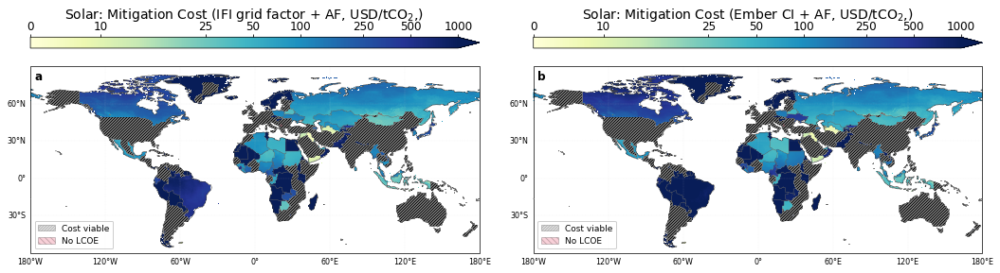


[Solar] abatement_cost
  Valid baseline cells (finite & >0): 34,483
  Total grid cells: 167,907
  Plotted positive cells after masking: 31,637
  Mean: 38402.396
  Median: 64.462
  P10: 18.189
  P90: 152.556
  Min: 3.499
  Max: 10602083.404
  Share < 10: 1.38% (all valid), 0.28% (all cells), below-benchmark: 12.34% (of all valid)
  Share < 25: 15.04% (all valid), 3.09% (all cells), below-benchmark: 12.34% (of all valid)
  Share < 50: 35.59% (all valid), 7.31% (all cells), below-benchmark: 12.34% (of all valid)
  Share < 100: 70.23% (all valid), 14.42% (all cells), below-benchmark: 12.34% (of all valid)

[Solar] abatement_cost_CI
  Valid baseline cells (finite & >0): 34,344
  Total grid cells: 167,907
  Plotted positive cells after masking: 31,637
  Mean: 9798.282
  Median: 86.564
  P10: 21.307
  P90: 284.349
  Min: 4.322
  Max: 197961.135
  Share < 10: 1.04% (all valid), 0.21% (all cells), below-benchmark: 12.39% (of all valid)
  Share < 25: 13.06% (all valid), 2.67% (all cells), below

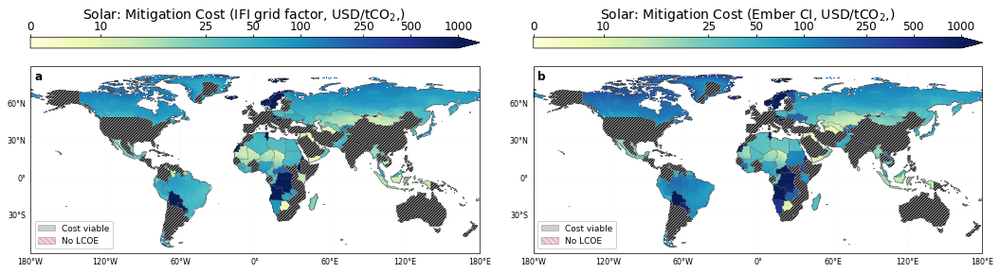


[Wind] abatement_cost_AF
  Valid baseline cells (finite & >0): 28,418
  Total grid cells: 167,907
  Plotted positive cells after masking: 28,689
  Mean: 3231583.120
  Median: 206.693
  P10: 39.162
  P90: 794495.185
  Min: 4.692
  Max: 4028613433.941
  Share < 10: 0.25% (all valid), 0.04% (all cells), below-benchmark: 18.08% (of all valid)
  Share < 25: 2.75% (all valid), 0.47% (all cells), below-benchmark: 18.08% (of all valid)
  Share < 50: 18.80% (all valid), 3.18% (all cells), below-benchmark: 18.08% (of all valid)
  Share < 100: 38.66% (all valid), 6.54% (all cells), below-benchmark: 18.08% (of all valid)

[Wind] abatement_cost_CI_AF
  Valid baseline cells (finite & >0): 28,323
  Total grid cells: 167,907
  Plotted positive cells after masking: 28,689
  Mean: 157923.913
  Median: 260.695
  P10: 39.009
  P90: 794495.185
  Min: 3.830
  Max: 855748.648
  Share < 10: 0.48% (all valid), 0.08% (all cells), below-benchmark: 18.14% (of all valid)
  Share < 25: 3.09% (all valid), 0.52% (al

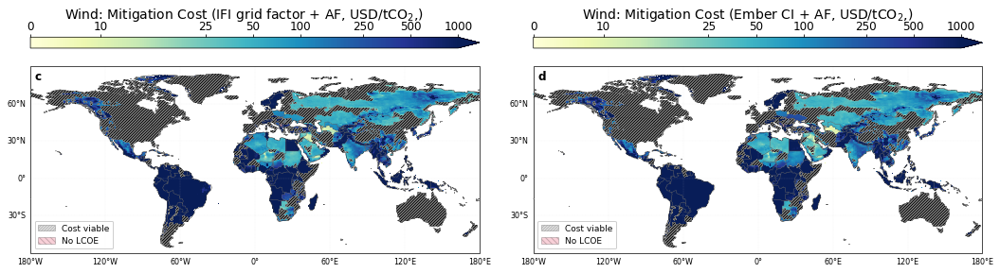


[Wind] abatement_cost
  Valid baseline cells (finite & >0): 28,418
  Total grid cells: 167,907
  Plotted positive cells after masking: 28,689
  Mean: 34184.052
  Median: 60.622
  P10: 16.636
  P90: 7944.952
  Min: 3.821
  Max: 40286134.339
  Share < 10: 2.26% (all valid), 0.38% (all cells), below-benchmark: 18.08% (of all valid)
  Share < 25: 18.62% (all valid), 3.15% (all cells), below-benchmark: 18.08% (of all valid)
  Share < 50: 44.39% (all valid), 7.51% (all cells), below-benchmark: 18.08% (of all valid)
  Share < 100: 62.28% (all valid), 10.54% (all cells), below-benchmark: 18.08% (of all valid)

[Wind] abatement_cost_CI
  Valid baseline cells (finite & >0): 28,323
  Total grid cells: 167,907
  Plotted positive cells after masking: 28,689
  Mean: 1660.506
  Median: 74.809
  P10: 17.613
  P90: 7944.952
  Min: 3.830
  Max: 8557.486
  Share < 10: 1.80% (all valid), 0.30% (all cells), below-benchmark: 18.14% (of all valid)
  Share < 25: 17.44% (all valid), 2.94% (all cells), below-b

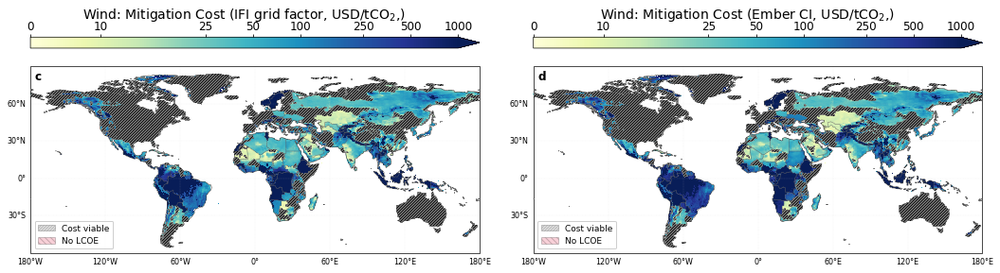


[Bioenergy] abatement_cost_AF
  Valid baseline cells (finite & >0): 7,161
  Total grid cells: 167,907
  Plotted positive cells after masking: 4,442
  Mean: 2222234.955
  Median: 206.008
  P10: 37.166
  P90: 993805.404
  Min: 13.516
  Max: 172130540.968
  Share < 10: 0.00% (all valid), 0.00% (all cells), below-benchmark: 43.09% (of all valid)
  Share < 25: 3.85% (all valid), 0.16% (all cells), below-benchmark: 43.09% (of all valid)
  Share < 50: 9.62% (all valid), 0.41% (all cells), below-benchmark: 43.09% (of all valid)
  Share < 100: 20.05% (all valid), 0.86% (all cells), below-benchmark: 43.09% (of all valid)

[Bioenergy] abatement_cost_CI_AF
  Valid baseline cells (finite & >0): 7,151
  Total grid cells: 167,907
  Plotted positive cells after masking: 4,442
  Mean: 86310.381
  Median: 438.812
  P10: 36.852
  P90: 41018.687
  Min: 9.551
  Max: 993805.404
  Share < 10: 0.39% (all valid), 0.02% (all cells), below-benchmark: 43.15% (of all valid)
  Share < 25: 4.38% (all valid), 0.19% 

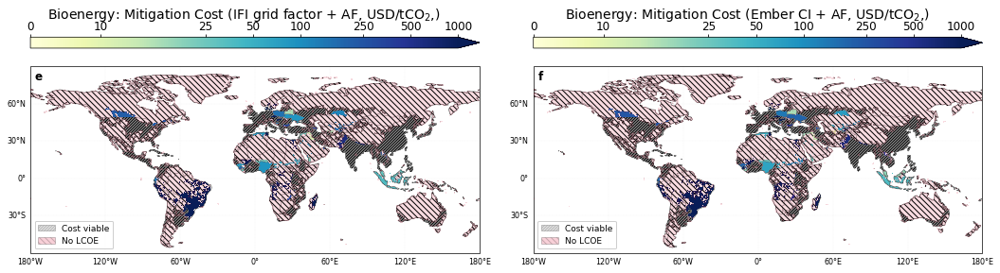


[Bioenergy] abatement_cost
  Valid baseline cells (finite & >0): 7,161
  Total grid cells: 167,907
  Plotted positive cells after masking: 4,442
  Mean: 24141.342
  Median: 53.753
  P10: 18.058
  P90: 27106.864
  Min: 8.192
  Max: 1721305.410
  Share < 10: 0.99% (all valid), 0.04% (all cells), below-benchmark: 43.09% (of all valid)
  Share < 25: 13.87% (all valid), 0.59% (all cells), below-benchmark: 43.09% (of all valid)
  Share < 50: 28.96% (all valid), 1.24% (all cells), below-benchmark: 43.09% (of all valid)
  Share < 100: 53.34% (all valid), 2.28% (all cells), below-benchmark: 43.09% (of all valid)

[Bioenergy] abatement_cost_CI
  Valid baseline cells (finite & >0): 7,151
  Total grid cells: 167,907
  Plotted positive cells after masking: 4,442
  Mean: 2378.203
  Median: 85.539
  P10: 18.022
  P90: 410.187
  Min: 7.733
  Max: 27106.864
  Share < 10: 2.46% (all valid), 0.10% (all cells), below-benchmark: 43.15% (of all valid)
  Share < 25: 18.07% (all valid), 0.77% (all cells), be

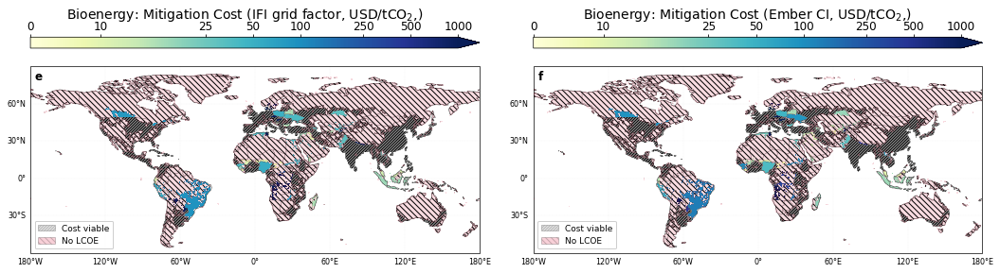


[Hydro] abatement_cost_AF
  Valid baseline cells (finite & >0): 6,520
  Total grid cells: 167,907
  Plotted positive cells after masking: 5,091
  Mean: 345968.477
  Median: 258.004
  P10: 67.483
  P90: 2071.539
  Min: 8.784
  Max: 90246862.413
  Share < 10: 0.31% (all valid), 0.01% (all cells), below-benchmark: 26.52% (of all valid)
  Share < 25: 2.32% (all valid), 0.09% (all cells), below-benchmark: 26.52% (of all valid)
  Share < 50: 4.45% (all valid), 0.17% (all cells), below-benchmark: 26.52% (of all valid)
  Share < 100: 28.93% (all valid), 1.12% (all cells), below-benchmark: 26.52% (of all valid)

[Hydro] abatement_cost_CI_AF
  Valid baseline cells (finite & >0): 6,530
  Total grid cells: 167,907
  Plotted positive cells after masking: 5,091
  Mean: 1541.220
  Median: 165.318
  P10: 58.979
  P90: 1731.239
  Min: 7.444
  Max: 40679.676
  Share < 10: 0.09% (all valid), 0.00% (all cells), below-benchmark: 26.54% (of all valid)
  Share < 25: 2.27% (all valid), 0.09% (all cells), bel

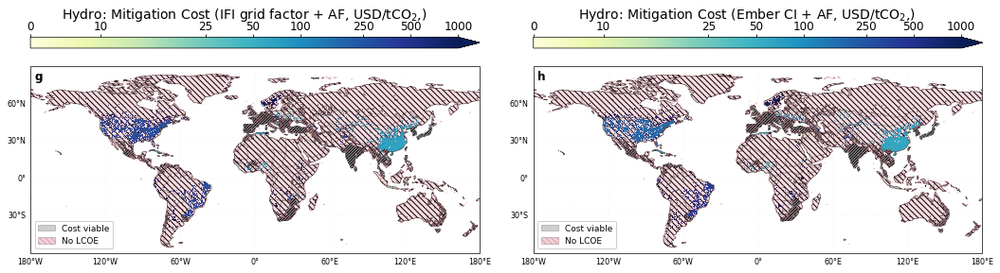


[Hydro] abatement_cost
  Valid baseline cells (finite & >0): 6,520
  Total grid cells: 167,907
  Plotted positive cells after masking: 5,091
  Mean: 3585.808
  Median: 22.782
  P10: 16.064
  P90: 208.632
  Min: 5.871
  Max: 902468.624
  Share < 10: 1.73% (all valid), 0.07% (all cells), below-benchmark: 26.52% (of all valid)
  Share < 25: 39.82% (all valid), 1.55% (all cells), below-benchmark: 26.52% (of all valid)
  Share < 50: 43.47% (all valid), 1.69% (all cells), below-benchmark: 26.52% (of all valid)
  Share < 100: 44.54% (all valid), 1.73% (all cells), below-benchmark: 26.52% (of all valid)

[Hydro] abatement_cost_CI
  Valid baseline cells (finite & >0): 6,530
  Total grid cells: 167,907
  Plotted positive cells after masking: 5,091
  Mean: 77.615
  Median: 32.226
  P10: 14.040
  P90: 240.163
  Min: 5.225
  Max: 406.797
  Share < 10: 2.62% (all valid), 0.10% (all cells), below-benchmark: 26.54% (of all valid)
  Share < 25: 30.37% (all valid), 1.18% (all cells), below-benchmark: 2

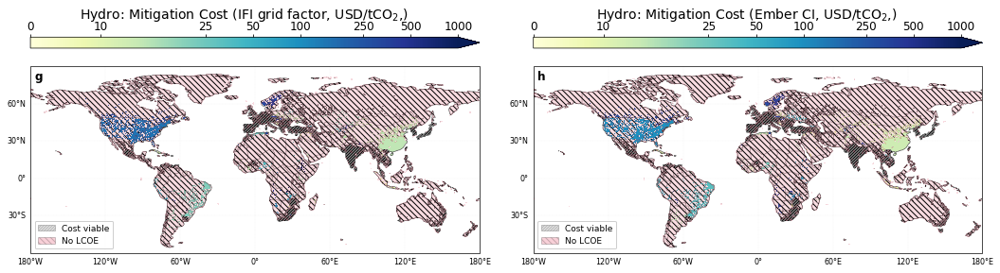


[Geothermal] abatement_cost_AF
  Valid baseline cells (finite & >0): 2,421
  Total grid cells: 167,907
  Plotted positive cells after masking: 2,073
  Mean: 423399.203
  Median: 2385.804
  P10: 1370.071
  P90: 28682.117
  Min: 25.229
  Max: 105313310.192
  Share < 10: 0.00% (all valid), 0.00% (all cells), below-benchmark: 29.90% (of all valid)
  Share < 25: 0.00% (all valid), 0.00% (all cells), below-benchmark: 29.90% (of all valid)
  Share < 50: 1.03% (all valid), 0.01% (all cells), below-benchmark: 29.90% (of all valid)
  Share < 100: 5.99% (all valid), 0.09% (all cells), below-benchmark: 29.90% (of all valid)

[Geothermal] abatement_cost_CI_AF
  Valid baseline cells (finite & >0): 2,360
  Total grid cells: 167,907
  Plotted positive cells after masking: 2,073
  Mean: 8027.666
  Median: 1993.878
  P10: 1938.000
  P90: 28682.117
  Min: 13.048
  Max: 75790.771
  Share < 10: 0.00% (all valid), 0.00% (all cells), below-benchmark: 30.68% (of all valid)
  Share < 25: 0.30% (all valid), 0.

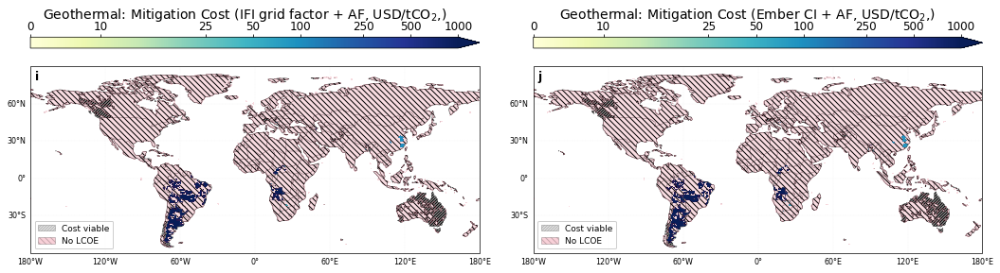


[Geothermal] abatement_cost
  Valid baseline cells (finite & >0): 2,421
  Total grid cells: 167,907
  Plotted positive cells after masking: 2,073
  Mean: 4504.277
  Median: 119.682
  P10: 23.858
  P90: 632.543
  Min: 10.971
  Max: 1053133.102
  Share < 10: 0.00% (all valid), 0.00% (all cells), below-benchmark: 29.90% (of all valid)
  Share < 25: 34.86% (all valid), 0.50% (all cells), below-benchmark: 29.90% (of all valid)
  Share < 50: 35.56% (all valid), 0.51% (all cells), below-benchmark: 29.90% (of all valid)
  Share < 100: 36.22% (all valid), 0.52% (all cells), below-benchmark: 29.90% (of all valid)

[Geothermal] abatement_cost_CI
  Valid baseline cells (finite & >0): 2,360
  Total grid cells: 167,907
  Plotted positive cells after masking: 2,073
  Mean: 211.154
  Median: 169.293
  P10: 19.939
  P90: 632.543
  Min: 11.925
  Max: 757.908
  Share < 10: 0.00% (all valid), 0.00% (all cells), below-benchmark: 30.68% (of all valid)
  Share < 25: 35.93% (all valid), 0.51% (all cells), be

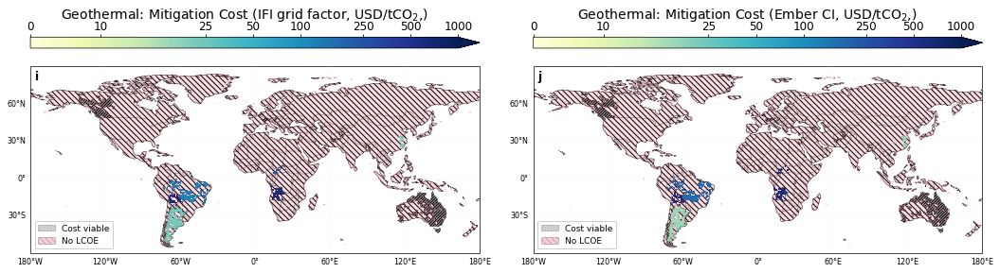


[Cheapest] abatement_cost_AF
  Valid baseline cells (finite & >0): 25,508
  Total grid cells: 167,907
  Plotted positive cells after masking: 20,290
  Mean: 2136133.503
  Median: 84.776
  P10: 28.960
  P90: 795044.323
  Min: 4.505
  Max: 733643378.218
  Share < 10: 0.62% (all valid), 0.09% (all cells), below-benchmark: 25.68% (of all valid)
  Share < 25: 4.47% (all valid), 0.68% (all cells), below-benchmark: 25.68% (of all valid)
  Share < 50: 24.35% (all valid), 3.70% (all cells), below-benchmark: 25.68% (of all valid)
  Share < 100: 45.82% (all valid), 6.96% (all cells), below-benchmark: 25.68% (of all valid)

[Cheapest] abatement_cost_CI_AF
  Valid baseline cells (finite & >0): 25,369
  Total grid cells: 167,907
  Plotted positive cells after masking: 20,290
  Mean: 575780.163
  Median: 81.292
  P10: 32.439
  P90: 28815.148
  Min: 3.830
  Max: 7911453.737
  Share < 10: 0.97% (all valid), 0.15% (all cells), below-benchmark: 25.82% (of all valid)
  Share < 25: 4.05% (all valid), 0.61

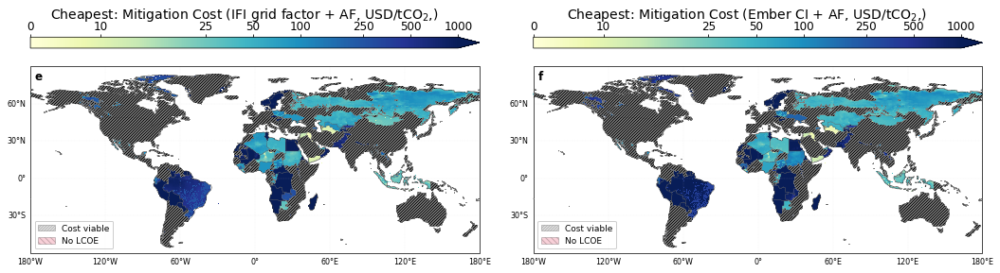


[Cheapest] abatement_cost
  Valid baseline cells (finite & >0): 25,508
  Total grid cells: 167,907
  Plotted positive cells after masking: 20,290
  Mean: 31541.454
  Median: 37.507
  P10: 13.231
  P90: 21685.491
  Min: 3.499
  Max: 7336433.782
  Share < 10: 3.30% (all valid), 0.50% (all cells), below-benchmark: 25.68% (of all valid)
  Share < 25: 24.33% (all valid), 3.70% (all cells), below-benchmark: 25.68% (of all valid)
  Share < 50: 51.86% (all valid), 7.88% (all cells), below-benchmark: 25.68% (of all valid)
  Share < 100: 68.81% (all valid), 10.45% (all cells), below-benchmark: 25.68% (of all valid)

[Cheapest] abatement_cost_CI
  Valid baseline cells (finite & >0): 25,369
  Total grid cells: 167,907
  Plotted positive cells after masking: 20,290
  Mean: 14220.902
  Median: 37.850
  P10: 13.318
  P90: 518.712
  Min: 3.830
  Max: 195070.391
  Share < 10: 2.95% (all valid), 0.45% (all cells), below-benchmark: 25.82% (of all valid)
  Share < 25: 21.94% (all valid), 3.31% (all cells

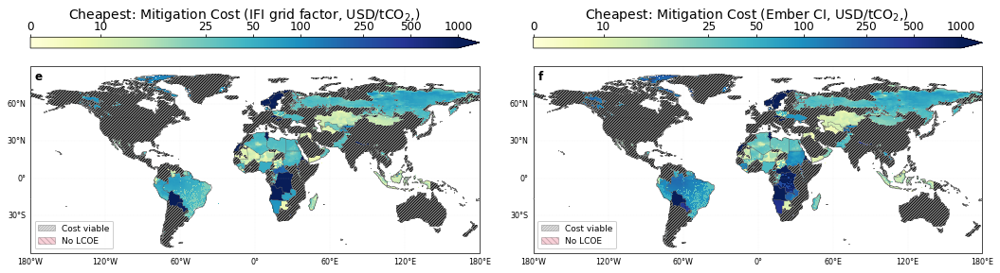

In [3]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

# --------------------------
# Global plotting style
# --------------------------
mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 6,
    "legend.fontsize": 8,
    "savefig.dpi": 600,
    "axes.linewidth": 0.7,
})

def _style_geo_axis(ax):
    ax.coastlines(linewidth=0.6, color="#444444")
    ax.add_feature(cfeature.BORDERS, linewidth=0.45, edgecolor="#666666")
    ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.35,
    color="lightgrey",
    alpha=0.45,
    linestyle="--",
    x_inline=False,
    y_inline=False,
    rotate_labels=False
)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = True
    gl.bottom_labels = True
    gl.xlocator = mticker.FixedLocator([-180, -120, -60, 0, 60, 120, 180])
    gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {"size": 8}
    gl.ylabel_style = {"size": 8}

PLOT_CFG = {
    # 1) Colorbar control
    "cbar_ticks": [0, 10, 25, 50, 100, 250, 500, 1000],  # set exactly what you want
    "cbar_ticklabels": ["0", "10", "25", "50", "100", "250", "500", "1000"],   # e.g. ["0","10","25","50","100","250","500","1000"] or None
    "cbar_extend": "max",  # "neither", "max", "min", "both"
    "cbar_label_size": 14,
    "cbar_tick_size": 12,
    "cbar_height": 0.018,      # thickness
    "cbar_pad": 0.03,         # distance above map axis

    # 2) Font sizes
    "font_family": "DejaVu Sans",
    "base_font_size": 12,
    "title_size": 20,          # <-- main panel titles
    "subtitle_size": 10,
    "axis_label_size": 9,
    "tick_label_size": 8,
    "legend_size": 8,
    "legend_title_size": 9,
    "panel_label_size": 12,    # a, b labels if used

    # 3) Additional quality improvements
    "figsize": (13, 8),
    "dpi_save": 600,
    "coastline_lw": 0.6,
    "border_lw": 0.45,
    "grid_lw": 0.35,
    "grid_alpha": 0.45,
    "title_pad": 8,
    "legend_framealpha": 0.95,
    "rasterized_mesh": True,   # smaller PDF files
}
def plot_technology_two_panel_clean(
    tech_file,
    global_results,
    abatement_var="abatement_cost",
    ci_var="abatement_cost_CI",
    lcoe_var="Calculated_LCOE",
    output_dir="./OUTPUT_FOLDER_REAL_INPUT",
    cmap="YlGnBu",
    figsize=(18, 9),
    cbar_ticks=(0, 10, 50, 100, 500, 1000),
    percentile_cap=99.0,
    fill_multiplier=1.25,
    print_summaries=True, 
    i=None,
    benchmark=None
):
    """
    Clean, publication-ready 2-panel map plot:
      (a) abatement_var
      (b) ci_var

    Includes:
    - Shared finite normalization across both panels
    - Fill value applied to BOTH variables:
        where var is NaN AND local LCOE exists -> fill = fill_multiplier * shared_vmax
    - Exclusive masks to avoid overlapping hatch artifacts:
        * purple hatched: below benchmark (<=0)
        * grey hatched: no local LCOE but global LCOE exists
    - Top colorbars with identical ticks
    - Optional printed summaries
    """

    import os
    import numpy as np
    import xarray as xr
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    import matplotlib.ticker as mticker
    from matplotlib.patches import Patch
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes

    # --------------------------
    # Basic style
    # --------------------------
    mpl.rcParams.update({
        "font.family": "DejaVu Sans",
        "font.size": 12,
        "axes.titlesize": 12,
        "axes.labelsize": 9,
        "legend.fontsize": 9,
        "savefig.dpi": 600,
        "axes.linewidth": 0.7,
    })

    def _style_geo_axis(ax, left_labels=True, bottom_labels=True):
        ax.coastlines(linewidth=0.6, color="#444444")
        ax.add_feature(cfeature.BORDERS, linewidth=0.45, edgecolor="#666666")
        ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())

        gl = ax.gridlines(
            crs=ccrs.PlateCarree(),
            draw_labels=True,
            linewidth=0.30,
            color="lightgrey",
            alpha=0.35,
            linestyle="--",
            x_inline=False,
            y_inline=False,
            rotate_labels=False
        )
        gl.top_labels = False
        gl.right_labels = False
        gl.left_labels = left_labels
        gl.bottom_labels = bottom_labels

        gl.xlocator = mticker.FixedLocator([-180, -120, -60, 0, 60, 120, 180])
        gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        gl.xlabel_style = {"size": 8}
        gl.ylabel_style = {"size": 8}


        def _add_top_colorbar(fig, ax, mappable, label, ticks):
            # slightly taller cbar to avoid clipped/hidden tick labels
            cax = ax.inset_axes([0.0, 1.045, 1.0, 0.055], transform=ax.transAxes)

            cb = fig.colorbar(mappable, cax=cax, orientation="horizontal", extend="neither")

            # Force exact tick locations and labels
            cb.locator = mticker.FixedLocator(ticks)
            cb.formatter = mticker.FixedFormatter([str(t) for t in ticks])
            cb.update_ticks()

            cb.ax.xaxis.set_ticks_position("top")
            cb.ax.xaxis.set_label_position("top")
            cb.ax.tick_params(axis="x", which="both",
                              top=True, labeltop=True,
                              bottom=False, labelbottom=False,
                              labelsize=8, pad=4)

            cb.set_label(label, fontsize=9, labelpad=4)
            cb.ax.spines["bottom"].set_visible(False)
            return cb

    def _summary(name, da_raw, da_pos, mask_below, mask_nolcoe, tech):
        """
        Prints:
          1) Share of ALL VALID cells
          2) Share of ALL cells
        for:
          - below-benchmark cells
          - no-local-LCOE cells

        Notes
        -----
        da_raw      : original variable before benchmark masking/fill filtering (xarray.DataArray)
        da_pos      : final positive-only plotting array (xarray.DataArray), used for value stats
        mask_below  : boolean/0-1 array for below-benchmark shading (same grid shape)
        mask_nolcoe : boolean/0-1 array for no-local-LCOE shading (same grid shape)
        """
        raw = da_raw.values
        vals = da_pos.values
        vals = vals[np.isfinite(vals)]

        below = (mask_below == 1)
        nolcoe = (mask_nolcoe == 1)

        # Denominators
        valid_base = np.isfinite(raw) & (raw > 0)   # "all valid cells" baseline
        n_valid = int(valid_base.sum())
        n_total = int(raw.size)

        # Numerators restricted to valid baseline (for share of valid)
        n_below_valid = int((below & valid_base).sum())
        n_nolcoe_valid = int((nolcoe & valid_base).sum())

        # Numerators over all cells (for share of all)
        n_below_all = int(below.sum())
        n_nolcoe_all = int(nolcoe.sum())

        # Percentages
        pct_below_valid = (100 * n_below_valid / n_valid) if n_valid else np.nan
        pct_nolcoe_valid = (100 * n_nolcoe_valid / n_valid) if n_valid else np.nan

        pct_below_all = (100 * n_below_all / n_total) if n_total else np.nan
        pct_nolcoe_all = (100 * n_nolcoe_all / n_total) if n_total else np.nan
        
       # Definitions (inside _summary)
        raw = da_raw.values
        below = (mask_below == 1)

        valid_base = np.isfinite(raw) & (raw > 0)   # all valid cells
        eligible = valid_base & (~below)            # valid and not below-benchmark

        n_valid = int(valid_base.sum())
        n_total = int(raw.size)
        n_below_valid = int((below & valid_base).sum())
        pct_below_valid = (100 * n_below_valid / n_valid) if n_valid else np.nan

        print(f"\n[{tech}] {name}")
        print(f"  Valid baseline cells (finite & >0): {n_valid:,}")
        print(f"  Total grid cells: {n_total:,}")

        # Existing value distribution summary from plotted positive cells
        n_plot = vals.size
        print(f"  Plotted positive cells after masking: {n_plot:,}")
        if n_plot > 0:
            print(f"  Mean: {np.nanmean(vals):.3f}")
            print(f"  Median: {np.nanmedian(vals):.3f}")
            print(f"  P10: {np.nanpercentile(vals, 10):.3f}")
            print(f"  P90: {np.nanpercentile(vals, 90):.3f}")
            print(f"  Min: {np.nanmin(vals):.3f}")
            print(f"  Max: {np.nanmax(vals):.3f}")
            for th in [10, 25, 50, 100]:
                n_lt = int(((raw < th) & eligible).sum())

                # 1) % of all valid cells
                pct_all_valid = (100 * n_lt / n_valid) if n_valid else np.nan

                # 2) % of all cells
                pct_all_cells = (100 * n_lt / n_total) if n_total else np.nan

                # 3) % below-benchmark of all valid cells (same for each th by definition requested)
                print(
                    f"  Share < {th}: "
                    f"{pct_all_valid:.2f}% (all valid), "
                    f"{pct_all_cells:.2f}% (all cells), "
                    f"below-benchmark: {pct_below_valid:.2f}% (of all valid)"
                )
            return np.nanmean(vals)
        else:
            print("  No valid positive plotted cells.")
            return np.nan
        
            
    def add_top_cbar(fig, ax, mappable, label, cfg):
        pos = ax.get_position()
        cax = fig.add_axes([pos.x0, pos.y1 + cfg["cbar_pad"], pos.width, cfg["cbar_height"]])

        cb = fig.colorbar(
            mappable,
            cax=cax,
            orientation="horizontal",
            extend=cfg["cbar_extend"]
        )

        # force top-only ticks
        cb.ax.tick_params(axis="x", which="both",
                          top=True, labeltop=True,
                          bottom=False, labelbottom=False,
                          labelsize=cfg["cbar_tick_size"], pad=1)
        cb.ax.xaxis.set_ticks_position("top")
        cb.ax.xaxis.set_label_position("top")

        # set user ticks
        if cfg["cbar_ticks"] is not None:
            cb.set_ticks(cfg["cbar_ticks"])
        if cfg["cbar_ticklabels"] is not None:
            cb.set_ticklabels(cfg["cbar_ticklabels"])

        cb.set_label(label, fontsize=cfg["cbar_label_size"], labelpad=2)
        cb.ax.spines["bottom"].set_visible(False)
        return cb


    # --------------------------
    # Load and validate
    # --------------------------
    ds = xr.open_dataset(tech_file)
    tech = os.path.basename(tech_file).split("_", 1)[1].split(".", 1)[0]
    if tech == "Full_Cheapest":
        tech = "Cheapest"

    for v in [abatement_var, ci_var, lcoe_var]:
        if v not in ds:
            raise KeyError(f"{v} not found in {tech_file}")
    if lcoe_var not in global_results:
        raise KeyError(f"{lcoe_var} not found in global_results")

    # --------------------------
    # Shared finite cap
    # --------------------------
    vals_a = ds[abatement_var].values
    vals_c = ds[ci_var].values
    fin_a = vals_a[np.isfinite(vals_a) & (vals_a > 0)]
    fin_c = vals_c[np.isfinite(vals_c) & (vals_c > 0)]

    if (fin_a.size + fin_c.size) == 0:
        shared_vmax = 10.0
    else:
        all_fin = np.concatenate([fin_a, fin_c]) if fin_c.size > 0 else fin_a
        shared_vmax = float(np.nanpercentile(all_fin, percentile_cap))
        shared_vmax = max(shared_vmax, 10.0)

    fill_value = fill_multiplier * shared_vmax

    # --------------------------
    # Fill NaNs where local LCOE exists (both vars)
    # --------------------------
    if benchmark is None:
        benchmark = ""
    da_a_raw = ds[abatement_var + benchmark]
    da_c_raw = ds[ci_var + benchmark]

    fill_mask_a = da_a_raw.isnull() & ds[lcoe_var].notnull()
    fill_mask_c = da_c_raw.isnull() & ds[lcoe_var].notnull()

    da_a = xr.where(fill_mask_a, fill_value, da_a_raw)
    da_c = xr.where(fill_mask_c, fill_value, da_c_raw)

    # --------------------------
    # Global-vs-local LCOE mask
    # --------------------------
    global_lcoe = global_results[lcoe_var].interp(
        latitude=ds["latitude"], longitude=ds["longitude"], method="nearest"
    )
    no_local_yes_global = ds[lcoe_var].isnull() & global_lcoe.notnull()

    # --------------------------
    # Exclusive shading masks (avoid stacked hatch artifacts)
    # --------------------------
    # Exclusive shading masks (avoid stacked hatch artifacts)
    if "Benchmark_LCOE" not in ds:
        raise KeyError(f"Benchmark_LCOE not found in {tech_file}")

    # Purple hatch: local LCOE below benchmark

    below_benchmark = (ds[lcoe_var] < ds["Benchmark_LCOE" + benchmark]*1000)

    # Keep masks exclusive from "no local LCOE but global exists"
    below_only = below_benchmark & (~no_local_yes_global)

    shade_a = below_only.values.astype(float)
    shade_c = below_only.values.astype(float)
    shade_nolcoe = no_local_yes_global.values.astype(float)

    # Positive-only plotting arrays
    da_a_pos = da_a.where(da_a > 0)
    da_c_pos = da_c.where(da_c > 0)
    
    # Remove locations below the benchmark
    da_a_pos = xr.where(below_benchmark, np.nan, da_a_pos)
    da_c_pos = xr.where(below_benchmark, np.nan, da_c_pos)
    
    # Shared norm
    shared_norm = mpl.colors.SymLogNorm(
        linthresh=25, linscale=1.0, vmin=0.0, vmax=1000, base=10
    )

    # Shared colorbar ticks clipped to vmax
    ticks = [t for t in cbar_ticks if t <= shared_vmax]
    if len(ticks) == 0:
        ticks = [0, round(shared_vmax, 2)]
    elif ticks[-1] != round(shared_vmax, 2):
        ticks.append(round(shared_vmax, 2))

    # --------------------------
    # Print summaries
    # --------------------------
    if print_summaries:
        abatement_mean = _summary(abatement_var, da_a_raw, da_a_pos, shade_a, shade_nolcoe, tech)
        ci_mean = _summary(ci_var, da_c_raw, da_c_pos, shade_c, shade_nolcoe, tech)
        print(f"[{tech}] Comparison of averages: {1-abatement_mean/ci_mean:.3f} (={abatement_mean} vs {ci_mean}")
        print(f"[{tech}] fill_value used: {fill_value:.3f} (={fill_multiplier} × shared_vmax {shared_vmax:.3f})")

    # --------------------------
    # Plot
    # --------------------------
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(1, 2, wspace=0.12)
    vmin = 0
    vmax = float(shared_vmax)
    ax1 = fig.add_subplot(gs[0, 0], projection=ccrs.PlateCarree())
    ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.PlateCarree())

    m1 = ax1.pcolormesh(
        ds["longitude"], ds["latitude"], da_a_pos.values,
        cmap=cmap, norm=shared_norm, shading="auto",
        transform=ccrs.PlateCarree(), rasterized=True
    )
    m2 = ax2.pcolormesh(
        ds["longitude"], ds["latitude"], da_c_pos.values,
        cmap=cmap, norm=shared_norm, shading="auto",
        transform=ccrs.PlateCarree(), rasterized=True
    )

    # Purple hatch (below benchmark)
    for ax, shade in [(ax1, shade_a), (ax2, shade_c)]:
        ax.contourf(
            ds["longitude"], ds["latitude"], shade,
            levels=[0.5, 1.5], hatches=["////////"], colors="none",
            transform=ccrs.PlateCarree(), zorder=3
        )
        ax.contourf(
            ds["longitude"], ds["latitude"], shade,
            levels=[0.5, 1.5], colors=["grey"], alpha=0.85,
            transform=ccrs.PlateCarree(), zorder=2.9
        )

    # Grey hatch (no local LCOE, global available)
    for ax in [ax1, ax2]:
        ax.contourf(
            ds["longitude"], ds["latitude"], shade_nolcoe,
            levels=[0.5, 1.5], hatches=["\\\\\\\\"], colors="none",
            transform=ccrs.PlateCarree(), zorder=3.2
        )
        ax.contourf(
            ds["longitude"], ds["latitude"], shade_nolcoe,
            levels=[0.5, 1.5], colors=["crimson"], alpha=0.15,
            transform=ccrs.PlateCarree(), zorder=3.1
        )

    _style_geo_axis(ax1)
    _style_geo_axis(ax2)
    letter = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "e", "f"]
    lbl_1 = letter[i]
    lbl_2 = letter[i+1]
    ax1.text(0.01, 0.98, lbl_1, transform=ax1.transAxes, va="top", ha="left",
                fontsize=12, fontweight="bold")
    
    ax2.text(0.01, 0.98, lbl_2, transform=ax2.transAxes, va="top", ha="left",
                fontsize=12, fontweight="bold")


    legend_handles = [
        Patch(facecolor="grey", edgecolor="black", hatch="////////", alpha=0.2, label="Cost viable"),
        Patch(facecolor="crimson", edgecolor="black", hatch="\\\\\\\\", alpha=0.2, label="No LCOE"),
    ]
    ax1.legend(handles=legend_handles, loc="lower left", frameon=True, framealpha=0.95)
    ax2.legend(handles=legend_handles, loc="lower left", frameon=True, framealpha=0.95)
    if benchmark=="":
        value = ""
    else:
        value = benchmark + "%"

    mapping = {
        "abatement_cost": "Mitigation Cost (IFI grid factor, USD/tCO$_2$,"+value+")",
        "abatement_cost_CI": "Mitigation Cost (Ember CI, USD/tCO$_2$,"+value+")",
        "abatement_cost_AF": "Mitigation Cost (IFI grid factor + AF, USD/tCO$_2$,"+value+")",
        "abatement_cost_CI_AF": "Mitigation Cost (Ember CI + AF, USD/tCO$_2$,"+value+")"
    }

    add_top_cbar(fig, ax1, m1, f"{tech}: {mapping.get(abatement_var, abatement_var)}", PLOT_CFG)
    add_top_cbar(fig, ax2, m2, f"{tech}: {mapping.get(ci_var, ci_var)}", PLOT_CFG)

    os.makedirs(output_dir, exist_ok=True)
    out_png = os.path.join(output_dir, f"Mitigation_2panel_{tech}_{abatement_var}"+benchmark+".png")
    out_pdf = os.path.join(output_dir, f"Mitigation_2panel_{tech}_{abatement_var}"+benchmark+".pdf")
    fig.savefig(out_png, bbox_inches="tight")
    fig.savefig(out_pdf, bbox_inches="tight")

    plt.show()
    i = i + 2
    ds.close()
    
    return i



# --------------------------
# Run for each technology
# --------------------------
i=0
j=0
for f in [
    "./RESULTS/CHECKFINALFullResults_Solar.nc",
    "./RESULTS/CHECKFINALFullResults_Wind.nc",
    "./RESULTS/CHECKFINALFullResults_Bioenergy.nc",
    "./RESULTS/CHECKFINALFullResults_Hydro.nc",
    "./RESULTS/CHECKFINALFullResults_Geothermal.nc",
    "./RESULTS/CHECKFINALFullResults_Full_Cheapest.nc"
]:

    i = plot_technology_two_panel_clean(
        tech_file=f,
        global_results=results,
        abatement_var="abatement_cost_AF",   # <--- choose input variable here
        ci_var="abatement_cost_CI_AF",
        lcoe_var="Calculated_LCOE",
        output_dir="./OUTPUT_FOLDER_REAL_INPUT",
        i=i
    )
    
    j = plot_technology_two_panel_clean(
        tech_file=f,
        global_results=results,
        abatement_var="abatement_cost",   # <--- choose input variable here
        ci_var="abatement_cost_CI",
        lcoe_var="Calculated_LCOE",
        output_dir="./OUTPUT_FOLDER_REAL_INPUT",
        i=j
    )
    


[Cheapest] abatement_cost
  Valid (>0) cells: 37,050
  Below-benchmark shaded cells: 12,187 (7.26%)
  No-local-LCOE shaded cells: 0 (0.00%)
  Mean: 29121.998
  Median: 39.823
  P10: 13.759
  P90: 191.062
  Min: 3.681
  Max: 10081751.723
  Share < 10: 5.10%
  Share < 25: 29.99%
  Share < 50: 60.32%
  Share < 100: 84.97%

[Cheapest] abatement_cost_CI
  Valid (>0) cells: 37,050
  Below-benchmark shaded cells: 12,187 (7.26%)
  No-local-LCOE shaded cells: 0 (0.00%)
  Mean: 11209.258
  Median: 47.528
  P10: 14.747
  P90: 309.641
  Min: 4.290
  Max: 195070.391
  Share < 10: 2.48%
  Share < 25: 26.45%
  Share < 50: 51.63%
  Share < 100: 79.29%
[Cheapest] Comparison of averages: -1.598 (=29121.997508740784 vs 11209.257676006027
[Cheapest] fill_value used: 195070.391 (=1.25 × shared_vmax 156056.313)


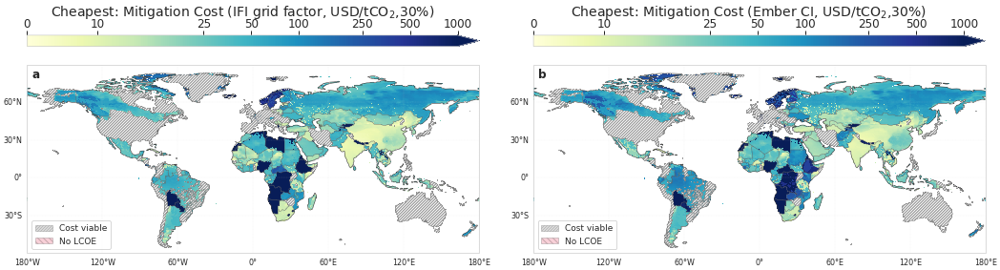


[Cheapest] abatement_cost
  Valid (>0) cells: 28,872
  Below-benchmark shaded cells: 20,365 (12.13%)
  No-local-LCOE shaded cells: 0 (0.00%)
  Mean: 27016.204
  Median: 36.921
  P10: 11.462
  P90: 133.601
  Min: 4.168
  Max: 9345478.864
  Share < 10: 7.44%
  Share < 25: 33.60%
  Share < 50: 64.48%
  Share < 100: 87.63%

[Cheapest] abatement_cost_CI
  Valid (>0) cells: 28,872
  Below-benchmark shaded cells: 20,365 (12.13%)
  No-local-LCOE shaded cells: 0 (0.00%)
  Mean: 8489.404
  Median: 38.700
  P10: 13.490
  P90: 239.726
  Min: 4.661
  Max: 195070.391
  Share < 10: 4.14%
  Share < 25: 32.14%
  Share < 50: 57.86%
  Share < 100: 83.69%
[Cheapest] Comparison of averages: -2.182 (=27016.20403085529 vs 8489.403741615426
[Cheapest] fill_value used: 195070.391 (=1.25 × shared_vmax 156056.313)


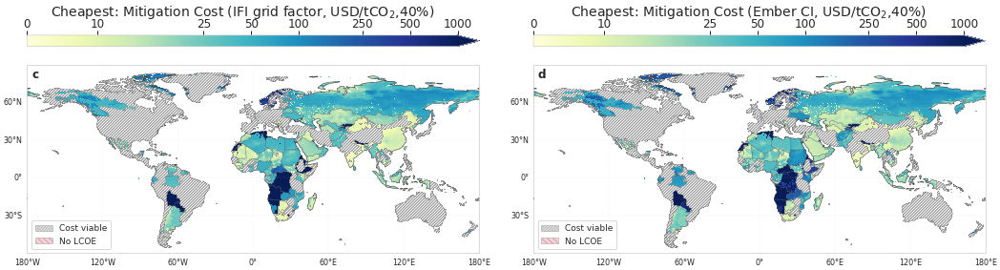


[Cheapest] abatement_cost
  Valid (>0) cells: 21,941
  Below-benchmark shaded cells: 27,296 (16.26%)
  No-local-LCOE shaded cells: 0 (0.00%)
  Mean: 26772.551
  Median: 36.760
  P10: 12.849
  P90: 111.015
  Min: 4.691
  Max: 8609206.172
  Share < 10: 5.72%
  Share < 25: 37.37%
  Share < 50: 66.57%
  Share < 100: 89.14%

[Cheapest] abatement_cost_CI
  Valid (>0) cells: 21,941
  Below-benchmark shaded cells: 27,296 (16.26%)
  No-local-LCOE shaded cells: 0 (0.00%)
  Mean: 7279.570
  Median: 37.007
  P10: 12.006
  P90: 224.024
  Min: 5.224
  Max: 195070.391
  Share < 10: 3.32%
  Share < 25: 34.33%
  Share < 50: 60.90%
  Share < 100: 83.86%
[Cheapest] Comparison of averages: -2.678 (=26772.551221318703 vs 7279.569896862928
[Cheapest] fill_value used: 195070.391 (=1.25 × shared_vmax 156056.313)


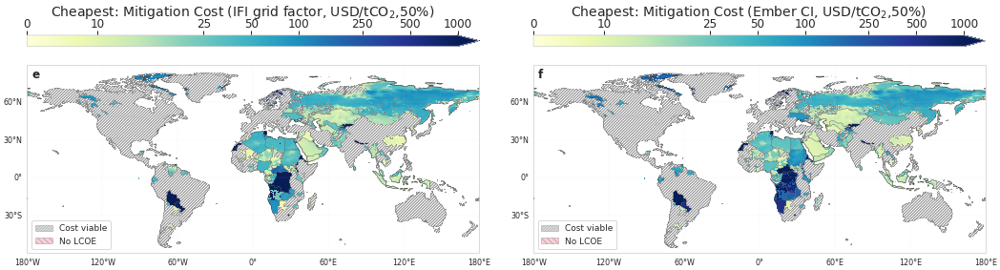


[Cheapest] abatement_cost
  Valid (>0) cells: 17,179
  Below-benchmark shaded cells: 32,058 (19.09%)
  No-local-LCOE shaded cells: 0 (0.00%)
  Mean: 27834.518
  Median: 37.483
  P10: 10.996
  P90: 96.699
  Min: 3.223
  Max: 7872933.146
  Share < 10: 7.10%
  Share < 25: 33.36%
  Share < 50: 70.03%
  Share < 100: 90.47%

[Cheapest] abatement_cost_CI
  Valid (>0) cells: 17,179
  Below-benchmark shaded cells: 32,058 (19.09%)
  No-local-LCOE shaded cells: 0 (0.00%)
  Mean: 7490.173
  Median: 36.907
  P10: 10.910
  P90: 202.195
  Min: 4.538
  Max: 195070.391
  Share < 10: 8.73%
  Share < 25: 30.53%
  Share < 50: 63.80%
  Share < 100: 83.31%
[Cheapest] Comparison of averages: -2.716 (=27834.51800296191 vs 7490.173355109031
[Cheapest] fill_value used: 195070.391 (=1.25 × shared_vmax 156056.313)


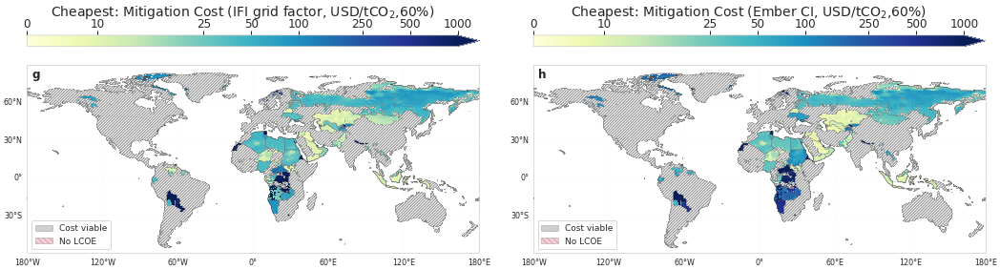


[Cheapest] abatement_cost
  Valid (>0) cells: 13,887
  Below-benchmark shaded cells: 35,350 (21.05%)
  No-local-LCOE shaded cells: 0 (0.00%)
  Mean: 26986.865
  Median: 33.763
  P10: 11.764
  P90: 87.072
  Min: 3.743
  Max: 7136660.454
  Share < 10: 7.51%
  Share < 25: 29.80%
  Share < 50: 71.33%
  Share < 100: 91.34%

[Cheapest] abatement_cost_CI
  Valid (>0) cells: 13,887
  Below-benchmark shaded cells: 35,350 (21.05%)
  No-local-LCOE shaded cells: 0 (0.00%)
  Mean: 6871.026
  Median: 33.676
  P10: 11.347
  P90: 188.323
  Min: 3.509
  Max: 195070.391
  Share < 10: 8.61%
  Share < 25: 30.80%
  Share < 50: 63.62%
  Share < 100: 82.25%
[Cheapest] Comparison of averages: -2.928 (=26986.865236934747 vs 6871.02566358307
[Cheapest] fill_value used: 195070.391 (=1.25 × shared_vmax 156056.313)


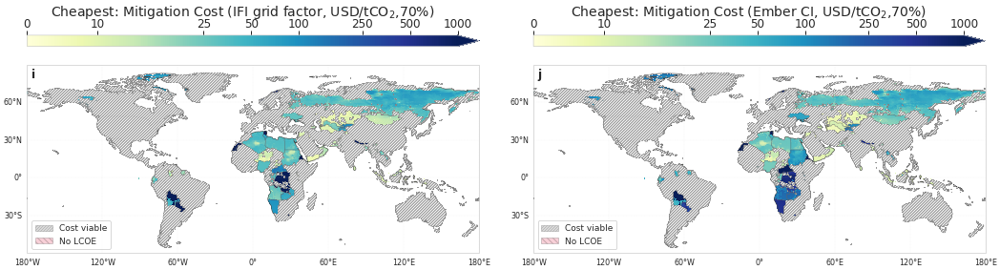

In [57]:
i=0
full_results = xr.open_dataset("./RESULTS/CHECKFINALFullResults_Full_Cheapest.nc")
for benchmark in ["30", "40", "50", "60", "70"]:
    i = plot_technology_two_panel_clean(
        tech_file=f,
        global_results=results,
        abatement_var="abatement_cost",   # <--- choose input variable here
        ci_var="abatement_cost_CI",
        lcoe_var="Calculated_LCOE",
        output_dir="./OUTPUT_FOLDER_REAL_INPUT",
        i=i,
        benchmark=benchmark
    )


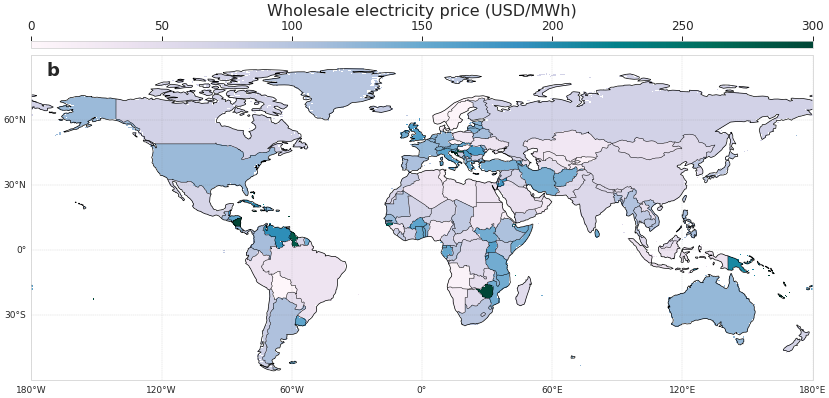

In [79]:
da = results["Benchmark_LCOE"] * 1000

fig = plt.figure(figsize=(14, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

# Plot raster
mesh = ax.pcolormesh(
    da["longitude"],
    da["latitude"],
    da.values,
    transform=ccrs.PlateCarree(),
    cmap="PuBuGn",
    vmin=0, vmax=300,
    shading="auto"
)

# Coastlines + borders
ax.coastlines(linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.text(0.02, 0.98, "b",
        transform=ax.transAxes,   # axes-relative coordinates
        ha="left", va="top",
        fontsize=18, fontweight="bold"
    )

# Limit to latitudes above -65
ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())

# Longitude/latitude ticks + labels
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.4,
    color="gray",
    alpha=0.4,
    linestyle="--"
)
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator([-180, -120, -60, 0, 60, 120, 180])
gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlabel_style = {"size": 9}
gl.ylabel_style = {"size": 9}

# Colorbar above, thin, map-width
pos = ax.get_position()
cax = fig.add_axes([pos.x0, pos.y1 + 0.015, pos.width, 0.018])
cbar = fig.colorbar(mesh, cax=cax, orientation="horizontal")
cbar.set_label("Wholesale electricity price (USD/MWh)", fontsize=16)
cbar.ax.xaxis.set_ticks_position("top")
cbar.ax.xaxis.set_label_position("top")
cbar.ax.tick_params(labelsize='medium')
plt.savefig("./OUTPUT_FOLDER_REAL_INPUT/Benchmark_LCOE.png")
plt.show()

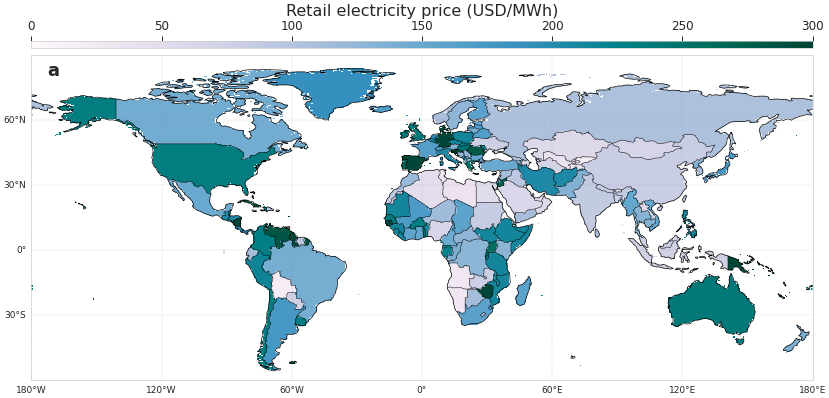

In [80]:
da = results["Benchmark_Price"]

fig = plt.figure(figsize=(14, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

# Plot raster
mesh = ax.pcolormesh(
    da["longitude"],
    da["latitude"],
    da.values,
    transform=ccrs.PlateCarree(),
    cmap="PuBuGn",
    vmin=0, vmax=300,
    shading="auto"
)

# Coastlines + borders
ax.coastlines(linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.text(0.02, 0.98, "a",
        transform=ax.transAxes,   # axes-relative coordinates
        ha="left", va="top",
        fontsize=18, fontweight="bold"
    )

# Limit to latitudes above -65
ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())

# Longitude/latitude ticks + labels
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.4,
    color="gray",
    alpha=0.4,
    linestyle="--"
)
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator([-180, -120, -60, 0, 60, 120, 180])
gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlabel_style = {"size": 9}
gl.ylabel_style = {"size": 9}

# Colorbar above, thin, map-width
pos = ax.get_position()
cax = fig.add_axes([pos.x0, pos.y1 + 0.015, pos.width, 0.018])
cbar = fig.colorbar(mesh, cax=cax, orientation="horizontal")
cbar.set_label("Retail electricity price (USD/MWh)", fontsize=16)
cbar.ax.xaxis.set_ticks_position("top")
cbar.ax.xaxis.set_label_position("top")
cbar.ax.tick_params(labelsize='medium')
plt.savefig("./OUTPUT_FOLDER_REAL_INPUT/Benchmark_Price.png")
plt.show()

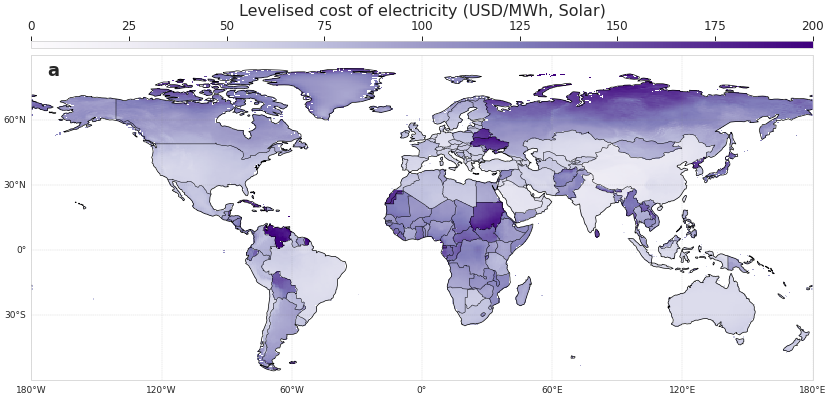

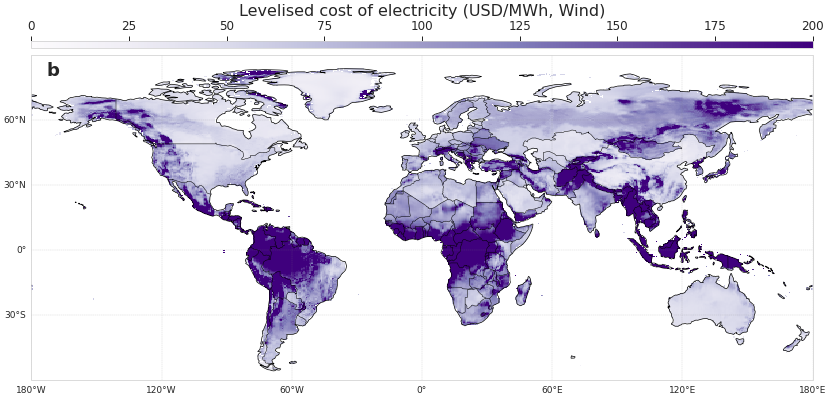

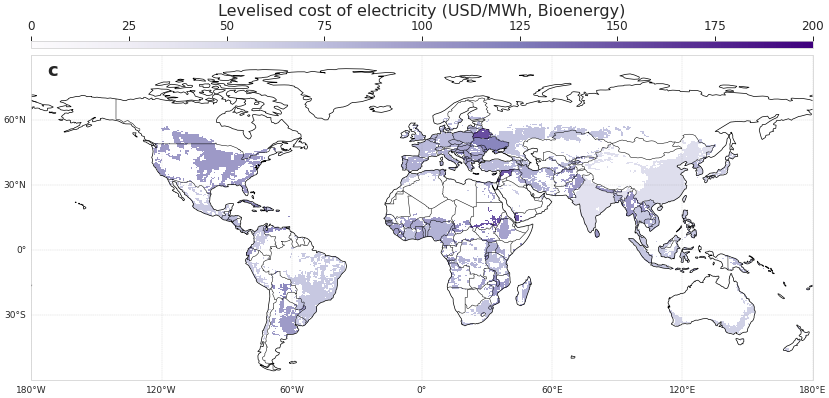

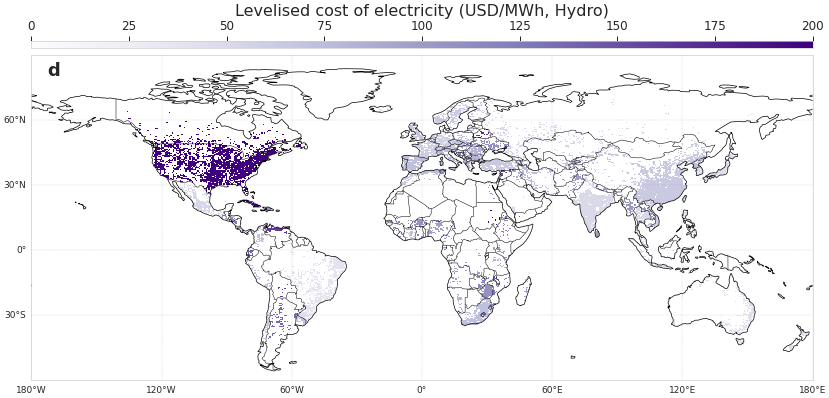

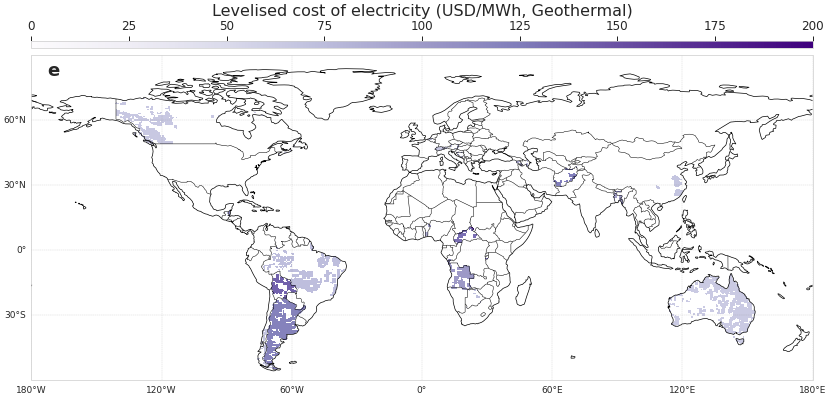

In [81]:
i = 0
for f in [
    "./RESULTS/FullResults_Solar.nc",
    "./RESULTS/FullResults_Wind.nc",
    "./RESULTS/FullResults_Bioenergy.nc",
    "./RESULTS/FullResults_Hydro.nc",
    "./RESULTS/FullResults_Geothermal.nc",
]:
    

    individual_results = xr.open_dataset(f)
    tech = os.path.basename(f).split("_", 1)[1].split(".", 1)[0]
    da = individual_results["Calculated_LCOE"]
    label = ["a", "b", "c", "d", "e"]
    
    fig = plt.figure(figsize=(14, 6))
    ax = plt.axes(projection=ccrs.PlateCarree())

    # Plot raster
    mesh = ax.pcolormesh(
        da["longitude"],
        da["latitude"],
        da.values,
        transform=ccrs.PlateCarree(),
        cmap="Purples",
        vmin=0, vmax=200,
        shading="auto"
    )

    # Coastlines + borders
    ax.coastlines(linewidth=0.7)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.text(0.02, 0.98, label[i],
            transform=ax.transAxes,   # axes-relative coordinates
            ha="left", va="top",
            fontsize=18, fontweight="bold"
        )

    # Limit to latitudes above -65
    ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())

    # Longitude/latitude ticks + labels
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=0.4,
        color="gray",
        alpha=0.4,
        linestyle="--"
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.FixedLocator([-180, -120, -60, 0, 60, 120, 180])
    gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {"size": 9}
    gl.ylabel_style = {"size": 9}

    # Colorbar above, thin, map-width
    pos = ax.get_position()
    cax = fig.add_axes([pos.x0, pos.y1 + 0.015, pos.width, 0.018])
    cbar = fig.colorbar(mesh, cax=cax, orientation="horizontal")
    cbar.set_label(f"Levelised cost of electricity (USD/MWh, {tech})", fontsize=16)
    cbar.ax.xaxis.set_ticks_position("top")
    cbar.ax.xaxis.set_label_position("top")
    cbar.ax.tick_params(labelsize='medium')
    plt.savefig(f"./OUTPUT_FOLDER_REAL_INPUT/Calculated_LCOE_{tech}.png")
    plt.show()
    i = i + 1

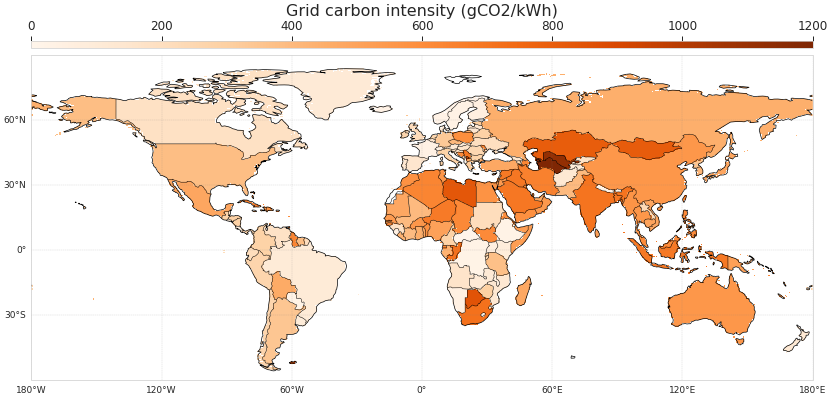

In [82]:
da = results["Electricity_CI"]

fig = plt.figure(figsize=(14, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

# Plot raster
mesh = ax.pcolormesh(
    da["longitude"],
    da["latitude"],
    da.values,
    transform=ccrs.PlateCarree(),
    cmap="Oranges",
    vmin=0, vmax=1200,
    shading="auto"
)

# Coastlines + borders
ax.coastlines(linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Limit to latitudes above -65
ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())

# Longitude/latitude ticks + labels
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.4,
    color="gray",
    alpha=0.4,
    linestyle="--"
)
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator([-180, -120, -60, 0, 60, 120, 180])
gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlabel_style = {"size": 9}
gl.ylabel_style = {"size": 9}

# Colorbar above, thin, map-width
pos = ax.get_position()
cax = fig.add_axes([pos.x0, pos.y1 + 0.015, pos.width, 0.018])
cbar = fig.colorbar(mesh, cax=cax, orientation="horizontal")
cbar.set_label("Grid carbon intensity (gCO2/kWh)", fontsize=16)
cbar.ax.xaxis.set_ticks_position("top")
cbar.ax.xaxis.set_label_position("top")
cbar.ax.tick_params(labelsize='medium')
plt.savefig("./OUTPUT_FOLDER_REAL_INPUT/Grid_Carbon_Intensity.png")
plt.show()